# Steam ownership prediction — model experiments

Compare **default KNN → tuned KNN → random forest → CatBoost → CatBoost + engineered features → CatBoost + tags/text → final CatBoost tuning → Random Forest tuning**.

This notebook complements `steam_eda_baseline_assessment.ipynb`; it does not modify it. It loads the cleaned, engineered `data/games-extra.parquet` and its manifest. Run `mle-proccess-data-extra.ipynb` first to generate that dataset; this notebook validates and selects stored features rather than cleaning or engineering them again.

**Business target:** estimate an existing game's cumulative ownership band. Estimated owners are a proxy for adoption, **not measured downloads, sales, revenue, or unique players**. These are snapshot data: this experiment cannot establish pre-launch forecasting performance or prove that changing a feature causes more downloads.

Run with the project's `.venv` kernel. Install dependencies using `python -m pip install -r requirements.txt`. The first run defaults to a bounded development sample; switch `QUICK_RUN=False` for the larger experiment. Model searches can take substantial time on CPU. No scores are claimed until the relevant cells have run.

## Why this experiment sequence?

The sequence answers three separate questions: **can the original learner be improved, does another model family suit the data better, and do richer features justify their cost?** It is an investigation plan, not an assumption that every later model will outperform an earlier one. The EDA identifies class imbalance, skewed numeric features and many binary genre/tag indicators, so accuracy alone is insufficient; compare macro F1, balanced accuracy, high-owner category performance and full-pipeline inference time.

| Experiment | Question and reason for including it |
| --- | --- |
| **Default KNN** | Establish a reproducible reference for the data scientists' initial approach on the current dataset and split. Include the majority-class predictor to show whether apparent accuracy exceeds what class imbalance alone provides. |
| **Tuned KNN** | Test whether scaling and better neighbor count, distance metric or voting weights address limitations of the original configuration before replacing its algorithm. This step changes preprocessing as well as hyperparameters, so the improvement is not attributable to tuning alone. |
| **Random Forest** | Test a nonlinear tree ensemble on the same baseline numeric, genre and tag features. This examines whether threshold-based interactions suit the data better than neighbor distances; the fixed configuration also introduces class weighting. |
| **CatBoost** | Compare a boosting-based tree ensemble with the forest. The `CatBoost baseline features` run shares the baseline feature set for an algorithm comparison; `CatBoost core` starts a separate, smaller numeric-plus-genres feature ladder. |
| **CatBoost + engineered features** | Hold CatBoost settings fixed and test whether stored transformations, platform/metadata counts, seasonality and missingness indicators add useful representations beyond the core inputs. Extra columns are hypotheses, not guaranteed improvements. |
| **CatBoost + tags/text** | Add binary tags, then description TF-IDF, separately to determine whether gameplay labels and listing language add signal beyond structured metadata. Compare their incremental benefit against vocabulary size, memory and inference cost. |
| **Final CatBoost tuning** | Search depth, learning rate, tree count, L2 regularization and class weighting for the engineered-plus-tags feature set chosen from development results. Separate this search from the fixed-parameter feature ladder so feature effects and tuning effects remain distinguishable. |
| **Random Forest tuning** | Give the alternative tree family its own optimization step rather than comparing a tuned CatBoost only with a fixed forest. Search capacity, sampling and class weighting on the same development folds, retaining the fixed forest if tuning does not improve the declared selection criterion. |

### Why Random Forest?

A forest combines randomized decision trees, reducing variance relative to relying on one tree. Tree splits can represent nonlinear relationships and interactions between game age, price, achievements and genre/tag indicators. They do not depend on Euclidean distances or require numeric standardization, making this a useful alternative for mixed numeric/binary inputs. These are model-family properties described in the [scikit-learn ensemble guide](https://scikit-learn.org/stable/modules/ensemble.html#random-forests-and-other-randomized-tree-ensembles).

For this project, `balanced_subsample` provides an explicit imbalance treatment, while depth/leaf constraints and sampling offer practical controls to explore. This is a reason to evaluate the forest, not evidence that it will recover more 100k+ games. Its memory, inference time and category metrics still need measurement. The initial comparison changes both learner and class weighting; it is not a pure learner-only ablation.

### Why CatBoost?

CatBoost builds gradient-boosted trees sequentially to reduce the training loss. It provides a different learning strategy from averaging randomized trees and can test whether sequentially learned nonlinear structure improves ownership-band prediction. This training mechanism is documented in [CatBoost's algorithm overview](https://catboost.ai/docs/en/concepts/algorithm-main-stages).

We choose it as a practical multiclass candidate with exposed controls for tree capacity, regularization, class weighting and CPU use, plus a probability-prediction interface for the service response ([CatBoostClassifier documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)). Its parameters allow us to explore accuracy, minority-class performance and serving cost together. Neither a better score nor faster inference is assumed in advance; the shared evaluations establish those tradeoffs. Predicted probabilities also require separate calibration assessment before treating them as reliable confidence estimates.

**Implementation-specific distinction:** this notebook supplies numeric features, binary genre/tag encodings and optional TF-IDF through a scikit-learn pipeline. It does **not** use CatBoost's native categorical or text processing, and numeric missing values are median-imputed before fitting. Those native capabilities therefore do not explain any improvement measured here. CatBoost is being evaluated as a boosted-tree learner under the existing preprocessing contract.

### How to interpret the comparisons

The early algorithm runs share baseline inputs, while the CatBoost core → engineered → tags → text ladder holds model settings fixed and changes feature groups. This separates algorithm comparisons from feature ablations. Tree methods may still benefit from count, seasonal and missingness representations; strictly monotonic log transforms mainly re-express existing information and are not automatically valuable for trees.

Use identical rows within each comparison and fit learned preprocessing inside five-fold training splits. Final CatBoost and Random Forest searches share the combined development folds; the fixed forest is re-evaluated there because earlier training-only CV used fewer rows. Search budgets and parameter spaces differ, so the results compare these implementations under the stated budgets, rather than proving one family universally superior. CatBoost tuning precedes forest tuning for workflow organization, not model ranking. Preserve the documented development-based deployment selection and use the final test set for reporting, including the high-owner confusion-matrix results, without further tuning against test scores.



## 1. Evaluation contract

- Validate the precomputed target against explicit ownership bounds: class 0 = [0, 20k), class 1 = [20k, 100k), class 2 = [100k, 200m]. Verify that no source interval crosses an internal threshold.
- Validate the exported coverage policy: release at least one year before **2023-07-05**, with a positive ownership midpoint. Sort by AppID, then reserve 20% using `random_state=42` without stratification, matching the original split recipe. Rows and labels can still differ from the old Parquet, so old scores are historical references rather than an exact paired comparison.
- Split the remaining development data into training/validation sets. All model variants see identical rows; sampling, if enabled, affects development data only. Fit imputers, scaling, genre/tag vocabularies and TF-IDF inside pipelines and inside each CV fold.
- Select models on **validation macro F1**, giving each ownership class equal weight. Report accuracy, balanced accuracy, weighted F1, ordinal MAE/RMSE and resource costs. Ordinal errors measure category distance, not errors in owner counts.
- Evaluate every model on the same training-only **5-fold stratified CV** splits, reporting mean/std predictive scores and inference times. Tune KNN using those five folds. Select the CatBoost feature variant on validation, then tune that variant and Random Forest on the same development-only CV folds. CV estimates after feature selection are selection diagnostics, not unbiased final scores.
- Open the test set once at the end for the business shortlist (tuned CatBoost + engineered + tags, fixed Random Forest, tuned Random Forest), the preselected deployment candidate if different, and the default KNN/majority references. Report confusion matrices and per-category metrics, emphasizing recall and precision for the 100k+ ownership class. Do not use those results for further tuning. A future-release or developer-group holdout is required before a forecasting claim.

### 1.1. Why expand the evaluation beyond `mle-exercise.ipynb`?

The original notebook reports **train/test ordinal RMSE**, a test **classification report** and a **row-normalized confusion matrix**. The classification report already includes accuracy, per-class precision/recall/F1/support, and macro/weighted averages ([scikit-learn report documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)). Those measures are retained here and made explicit across experiments, rather than all being newly introduced. The additions include balanced accuracy, ordinal MAE, extreme-class error rate, systematic five-fold summaries, inference/training costs, paired bootstrap intervals, and business-oriented counts for the high-owner class.

We need several perspectives because the dataset is imbalanced, owner bands are ordered, clients particularly value **100k+ owner games**, and the model must eventually serve predictions. A model can have high accuracy while missing most popular games; two equally accurate models can make very different category errors or have different inference costs. No single score captures all these requirements. The explanations below describe the existing implementation; they do not add new scoring code or change the selection rule.

### 1.2. Overall predictive metrics

Here `y` is the true class and `ŷ` the predicted class: 0 = <20k, 1 = 20k–<100k, 2 = 100k+. Scores use discrete predicted labels.

| Metric / output column | Meaning and preferred direction | Reason for including it |
| --- | --- | --- |
| **Accuracy** (`accuracy`) | Fraction of games assigned to the correct band; higher is better. | Give an easily understood overall success rate and retain continuity with the original report. Always compare against the majority predictor because frequent low-owner games dominate it. |
| **Balanced accuracy** (`balanced_accuracy`) | Mean recall across the classes present in the evaluated data; higher is better. With all three classes present, an always-majority predictor scores 1/3. | Check whether the model recognizes each actual category rather than succeeding mainly on the largest one. Unlike F1, it summarizes recall without precision. See the [balanced-accuracy definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html). |
| **Macro F1** (`macro_f1`) | Arithmetic mean of the three class F1 scores, with equal class weights; higher is better. | Use as the primary selection score so the smaller ownership categories contribute equally. It considers both precision and recall, but does not specifically prioritize the highest class over the middle class. |
| **Weighted F1** (`weighted_f1`) | Average class F1 weighted by actual class support; higher is better. | Retain a summary reflecting the observed mix of games. Compare with macro F1: a strong weighted score can coexist with weak minority-class performance. |
| **Ordinal MAE** (`ordinal_mae`) | Mean absolute class-step error, `mean(abs(y − ŷ))`; lower is better, range 0–2. | Distinguish a one-band mistake from a two-band mistake in an intuitive average category distance. |
| **Ordinal RMSE** (`ordinal_rmse`) | Square root of the mean squared class-step error; lower is better, range 0–2. | Retain the original notebook's ordinal perspective while penalizing extreme mistakes more strongly. A two-step error contributes 4 before averaging, versus 1 for a one-step error ([RMSE reference](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)). |
| **Extreme-class error rate** (`extreme_error_rate`) | Fraction with `abs(y − ŷ) = 2`; lower is better. | Directly expose confusion between <20k and 100k+, which an aggregate score may conceal. It combines both directions; the high-owner report separately counts popular games predicted in the lowest band. |

F1 definitions and support weighting follow the [precision/recall/F-score reference](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html). Macro F1 is the mean of class-specific F1 scores, not the F1 calculated from average precision and average recall.

**Interpretation limits:** ordinal metrics use equally spaced IDs even though ownership bands have unequal widths. They measure category distance, not errors in owner or download counts, and treat overestimation and underestimation symmetrically. None of these metrics directly measures revenue or partnership returns. Weighted F1 and accuracy are sensitive to the population's class mix.

### 1.3. Per-category metrics and the high-owner business view

For a category treated as “positive,” TP = correct predictions of that category, FN = actual members assigned elsewhere, and FP = other games incorrectly assigned to it. Their definitions are consistent with the original classification report, but section 12 adds explicit counts and a business-priority summary.

| Metric / diagnostic | Definition | Reason for including it |
| --- | --- | --- |
| **Precision** | `TP / (TP + FP)` | Measure how trustworthy a category flag is. High-owner precision addresses how many games flagged for popular-game follow-up actually belong to the 100k+ band. |
| **Recall** | `TP / (TP + FN)` | Measure category coverage. High-owner recall addresses how many actual popular games are found; low recall signals missed potential opportunities. |
| **Per-class F1** | `2TP / (2TP + FP + FN)` | Summarize precision and recall together within each category, so gains in the majority class cannot conceal weak high-owner performance. It gives neither business error type an explicit monetary cost. |
| **Support / actual high-owner games** | Number of actual games in a category (`TP + FN`) | Show the denominator behind a score and whether a category has enough examples to support a useful interpretation. Support is context, not a score to maximize. |
| **Predicted count / flagged high-owner games** | Number assigned to the category (`TP + FP`) | Show the volume of proposed follow-up work. A high recall achieved by flagging almost every game can impose a large review burden. |
| **True positives / identified high-owner games** | Correctly identified members of the category | Translate recall into a concrete count of correctly identified popular games. |
| **False negatives / missed high-owner games** | Actual members predicted elsewhere | Make missed popular games visible in business-readable units. These are classification misses, not a measured number of lost partnerships. |
| **False positives / false high-owner flags** | Other categories predicted as the category of interest | Quantify incorrect popular-game flags that could consume client attention. |
| **High-owner games predicted in the lowest band** | Confusion-matrix count for actual class 2, predicted class 0 | Isolate the most severe underestimation among the games clients prioritize. |
| **Confusion-matrix counts** | Actual classes on rows, predicted classes on columns | Reveal the direction and volume of errors rather than just their aggregate frequency. |
| **Row fractions** | Cell count divided by the actual-category row total | Compare prediction patterns across unequal class sizes; diagonal entries are class recall. |
| **Column fractions** | Cell count divided by the predicted-category column total | Show the composition of each predicted group; diagonal entries are class precision. These fractions are exported alongside the matrices. |

In the final category table, recall is **NaN when a category has no actual examples**; precision is set to zero when there are no predictions for it. F1 is zero when its denominator is zero. Empty confusion-matrix rows/columns have undefined exported fractions. Check support and denominators before interpreting these conventions. The “100k+” category spans a very wide ownership range and cannot distinguish a 100k-owner title from a blockbuster within that band.

### 1.4. Inference and training cost metrics

The service must preprocess game inputs as well as run the classifier, so timing includes the **complete fitted pipeline's `predict` call**. After an untimed one-row warm-up, the benchmark times repeated full batches; it reports the median duration (normally three repetitions, one in smoke mode).

| Timing output | Meaning and preferred direction | Reason for including it |
| --- | --- | --- |
| `inference_seconds` | Median batch prediction wall time; lower is better for the same workload. | Measure the total cost of processing an evaluated batch, including imputation and encodings. |
| `inference_ms_per_game` | `1000 × median seconds / batch size`; lower is better. | Compare amortized per-game cost across candidates. `predict_ms_per_game` is an alias, not a separate metric. |
| `inference_games_per_second` | `batch size / median seconds`; higher is better. | Express capacity in business-friendly units for batch scoring. It is the reciprocal view of the same timing, not independent evidence. |
| `inference_std_seconds` | Standard deviation across repeated batch timings. | Flag local timing variability. One smoke repetition necessarily gives zero variability and establishes no timing stability. |
| `inference_batch_size` | Number of games timed. | Supply workload context: per-game throughput depends on batching. This is not a score to optimize by changing the evaluation sample. |
| `fit_seconds` / fold fit time | Time spent fitting a pipeline, excluding evaluation prediction. | Estimate retraining cost and identify models that are expensive to maintain. Fold fit time includes preprocessing fitting. |
| `fit_or_search_seconds` | A single pipeline fit, or the supplied elapsed search time for a tuned candidate. | Track experiment cost, while distinguishing fitting one model from exploring many configurations. These two kinds of duration are not directly equivalent. |
| `cv_total_seconds` / `evaluation_or_search_seconds` | Total elapsed CV evaluation or search time, as named. | Make five-fold and tuning budgets visible; they include multiple fits and scoring work rather than only the final estimator fit. |

`train_*` timing fields apply the same benchmark to training rows; validation/test fields measure their respective workloads. Negative timing scorers (`neg_inference_*`) are an internal search convention, and exported readable timings restore positive values. Lower positive time is better; the search itself refits on macro F1, not speed.

These are local CPU batch measurements. They exclude API validation, HTTP/network overhead, queuing, startup and the probability-response workload (`predict_proba`). They are **not single-request response latency or a production load test**. Match hardware, thread settings, batch size and run mode before comparing resource costs.

### 1.5. Stability, uncertainty and comparative diagnostics

| Reported summary | Why it is useful and how to interpret it |
| --- | --- |
| **Five-fold mean and standard deviation** (`cv_mean_*`, `cv_std_*`, search `mean_test_*` / `std_test_*`) | Describe average predictive performance or timing and variation across the same stratified folds. A strong mean with large variation merits investigation. Fold standard deviation is not a confidence interval, and reused search folds produce post-selection diagnostics. See the [cross-validation guide](https://scikit-learn.org/stable/modules/cross_validation.html). |
| **Training macro F1 versus validation macro F1** | Diagnose a possible generalization gap; high training performance with substantially weaker validation performance suggests overfitting. Training performance alone does not establish quality on unseen games. |
| **Macro-F1 change versus the reference** | Express improvement in absolute score units over default KNN or the paired fixed forest, depending on the table. A change of 0.02 is two score percentage points, not a 2% relative gain. Compare scores evaluated on the same rows/folds. |
| **95% bootstrap intervals for candidate macro F1 and its change versus KNN** | Quantify test-sample variation for the fitted selected candidate. The code resamples within actual classes and uses the same sampled games for both models, preserving the paired comparison and observed class counts. Percentile limits are the 2.5th and 97.5th percentiles of 500 resamples (30 for execution checks). They do not include retraining, model-selection uncertainty or future distribution shift; an interval spanning zero does not establish a clear positive gain on this sample. |

**Decision rule:** retain validation macro F1 as the declared family-selection metric, with ordinal RMSE and inference time as tie-breakers; use development CV macro F1 for the implemented hyperparameter searches and the fixed-versus-tuned forest decision. High-owner metrics explain the business tradeoff without silently changing that rule after observing test results. If stakeholders want a recall-first policy, define and select it on development data before evaluating on a fresh holdout. The existing metrics assess predicted classes; probability calibration and probability-based ranking quality remain separate future assessments.



In [3]:
from pathlib import Path
from time import perf_counter
import hashlib
import importlib.metadata
import json
import os
import sys
import platform
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    mean_absolute_error, root_mean_squared_error, classification_report,
    ConfusionMatrixDisplay)
try:
    from catboost import CatBoostClassifier
except ImportError as exc:
    raise ImportError("Install project dependencies: python -m pip install -r requirements.txt") from exc

SEED = 42
QUICK_RUN = True
SMOKE_TEST = os.environ.get("STEAM_SMOKE_TEST") == "1"  # validation only; never report as experiment results
N_JOBS = min(4, os.cpu_count() or 1)
INFERENCE_REPEATS = 1 if SMOKE_TEST else 3
DEV_LIMIT = 600 if SMOKE_TEST else (6000 if QUICK_RUN else None)
CV_FOLDS = 5  # same five folds in smoke, quick and full modes
KNN_SEARCH_ITER = 1 if SMOKE_TEST else (6 if QUICK_RUN else 24)
CAT_SEARCH_ITER = 1 if SMOKE_TEST else (6 if QUICK_RUN else 24)
CAT_ITERATIONS = 20 if SMOKE_TEST else (250 if QUICK_RUN else 700)
RF_TREES = 20 if SMOKE_TEST else (200 if QUICK_RUN else 500)
TEXT_FEATURES = 150 if SMOKE_TEST else (1500 if QUICK_RUN else 5000)
OBSERVATION_DATE = pd.Timestamp("2023-07-05")
EXPECTED_DATASET_VERSION = "steam-games-extra-v1"
CLASSES = [0, 1, 2]
CLASS_NAMES = ["0–<20k owners", "20k–<100k owners", "100k–200m owners"]
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "games-extra.parquet").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Cannot find data/games-extra.parquet. Run assessment_1_modeling/notebooks/mle-proccess-data-extra.ipynb first.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from steam_data import OWNER_COLUMNS, OWNER_LB, OWNER_UB, OWNER_MID, ownership_target
# steam_service is the installed package in assessment_2_production.
# Support an uninstalled source checkout when opening this notebook directly.
if str(ROOT / "assessment_2_production") not in sys.path:
    sys.path.insert(0, str(ROOT / "assessment_2_production"))
from steam_service.features import BASE_NUMERIC, ENGINEERED, split_labels
DATA_PATH = ROOT / "data" / "games-extra.parquet"
DATA_MANIFEST_PATH = DATA_PATH.with_suffix(".manifest.json")
RAW_MODEL_COLUMNS = ["Genres", "Tags", "About the game"]
MODEL_COLUMNS = BASE_NUMERIC + ENGINEERED + RAW_MODEL_COLUMNS
RUN_LABEL = "smoke" if SMOKE_TEST else ("quick" if QUICK_RUN else "full")
OUTPUT = ROOT / "artifacts" / "steam_experiments" / RUN_LABEL
OUTPUT.mkdir(parents=True, exist_ok=True)
print({"mode": RUN_LABEL, "development_limit": DEV_LIMIT, "CV_folds": CV_FOLDS,
       "workers": N_JOBS, "output": str(OUTPUT)})

{'mode': 'quick', 'development_limit': 6000, 'CV_folds': 5, 'workers': 4, 'output': '/mnt/c/Workspace3/machine-learning-engineer-amsterdam (29)/artifacts/steam_experiments/quick'}


## 2. Load the engineered dataset and validate its contract

`mle-proccess-data-extra.ipynb` owns data cleaning, ownership/target construction and deterministic feature engineering. Load its Parquet and manifest, then run checks without changing stored values or dropping rows:

- Expected dataset version and **2023-07-05** observation date; output checksum and recorded dimensions.
- Required columns, unique/nonmissing `steam_appid`, matching AppID aliases and sorted IDs.
- Ownership bounds, midpoint `(lb + ub) / 2`, deterministic class mapping and one-year eligibility.
- Numeric feature types and absence of infinity; raw text columns remain strings. Missing numeric values are allowed for fold-fitted imputation.
- Explicit model-input allowlist excludes ownership, targets, engagement outcomes, identities and any globally encoded legacy indicators.

A failed check means the dataset should be regenerated or its version/feature contract deliberately updated. No CSV read, duplicate removal, text normalization, target reassignment or feature calculation occurs here. The ownership check compares stored labels; it does not replace them.

In [4]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def validate_engineered_dataset(frame, metadata):
    if metadata.get("dataset_version") != EXPECTED_DATASET_VERSION:
        raise ValueError("Unexpected dataset version; review or regenerate the preprocessing export.")
    if metadata.get("observation_date") != str(OBSERVATION_DATE.date()):
        raise ValueError("Dataset observation date does not match the experiment.")
    if metadata.get("class_mapping") != dict(zip(map(str, CLASSES), CLASS_NAMES)):
        raise ValueError("Dataset class mapping differs from the experiment contract.")
    if metadata.get("existing_experiment_features") != MODEL_COLUMNS:
        raise ValueError("Dataset model feature contract differs from the experiment allowlist.")
    required = {"steam_appid", "AppID", "release_date", "Estimated owners", "target", *OWNER_COLUMNS, *MODEL_COLUMNS}
    if not frame.columns.is_unique or not required <= set(frame):
        raise ValueError(f"Missing or duplicated dataset columns: {sorted(required - set(frame))}")
    if (len(frame) != metadata.get("retained_rows")
            or len(frame.columns) != metadata.get("column_count")):
        raise ValueError("Dataset dimensions do not match its manifest.")
    if frame.empty or frame["steam_appid"].isna().any() or not frame["steam_appid"].is_unique:
        raise ValueError("Dataset requires unique, nonmissing steam_appid values.")
    if not frame["steam_appid"].is_monotonic_increasing or not frame["steam_appid"].equals(frame["AppID"]):
        raise ValueError("AppID aliases must agree and rows must already be sorted by steam_appid.")
    if (not all(pd.api.types.is_numeric_dtype(frame[c]) for c in [*OWNER_COLUMNS, *BASE_NUMERIC, *ENGINEERED])
            or not pd.api.types.is_integer_dtype(frame["target"])):
        raise ValueError("Stored feature/ownership columns must be numeric and target must be integer.")
    if (not np.isfinite(frame[OWNER_COLUMNS].to_numpy(dtype=float)).all()
            or not np.allclose(frame[OWNER_MID], (frame[OWNER_LB] + frame[OWNER_UB]) / 2, atol=1e-8, rtol=0)
            or not frame[OWNER_MID].gt(0).all()):
        raise ValueError("Invalid stored ownership bounds or midpoint.")
    expected_target = ownership_target(frame)
    if set(frame["target"]) != set(CLASSES) or not np.array_equal(frame["target"], expected_target):
        raise ValueError("Stored target labels do not match ownership bands.")
    if (not pd.api.types.is_datetime64_any_dtype(frame["release_date"])
            or frame["release_date"].isna().any()
            or not frame["release_date"].le(OBSERVATION_DATE - pd.DateOffset(years=1)).all()):
        raise ValueError("Release dates violate the exported eligibility policy.")
    if np.isinf(frame[BASE_NUMERIC + ENGINEERED].to_numpy(dtype=float)).any():
        raise ValueError("Stored numeric model features contain infinity.")
    for column in RAW_MODEL_COLUMNS:
        if frame[column].isna().any() or not frame[column].map(lambda value: isinstance(value, str)).all():
            raise ValueError(f"{column} must contain already-cleaned strings, including empty strings.")
    forbidden = {"target", "AppID", "steam_appid", "Estimated owners", *OWNER_COLUMNS,
                 *metadata.get("analysis_only_columns", []), *metadata.get("legacy_global_one_hot_columns", [])}
    if forbidden & set(MODEL_COLUMNS):
        raise ValueError("Outcome, identity or analysis-only columns appear in model inputs.")


def load_engineered_dataset(data_path, manifest_path):
    if not data_path.is_file() or not manifest_path.is_file():
        raise FileNotFoundError("Missing engineered Parquet or manifest; run mle-proccess-data-extra.ipynb first.")
    metadata = json.loads(manifest_path.read_text(encoding="utf-8"))
    checksum = file_sha256(data_path)
    if metadata.get("output_file") != data_path.name or metadata.get("output_sha256") != checksum:
        raise ValueError("Parquet filename/checksum does not match its manifest; regenerate the dataset.")
    frame = pd.read_parquet(data_path).reset_index(drop=True)
    validate_engineered_dataset(frame, metadata)
    return frame, metadata, checksum


frame, dataset_metadata, dataset_sha256 = load_engineered_dataset(DATA_PATH, DATA_MANIFEST_PATH)
print(f"Validated {dataset_metadata['dataset_version']}: {len(frame):,} games, {len(frame.columns):,} columns")
display(frame[["Estimated owners", *OWNER_COLUMNS, "target"]].drop_duplicates().sort_values(OWNER_LB))

Validated steam-games-extra-v1: 58,614 games, 85 columns


,Estimated owners,Estimated owners (lb),Estimated owners (ub),Estimated owners (mid),target
26,0 - 20000,0.0,20000.0,10000.0,0
28,20000 - 50000,20000.0,50000.0,35000.0,1
33,50000 - 100000,50000.0,100000.0,75000.0,1
31,100000 - 200000,100000.0,200000.0,150000.0,2
44,200000 - 500000,200000.0,500000.0,350000.0,2
29,500000 - 1000000,500000.0,1000000.0,750000.0,2
45,1000000 - 2000000,1000000.0,2000000.0,1500000.0,2
12,2000000 - 5000000,2000000.0,5000000.0,3500000.0,2
1,5000000 - 10000000,5000000.0,10000000.0,7500000.0,2
0,10000000 - 20000000,10000000.0,20000000.0,15000000.0,2


### 2.1. Select stored model features

Select the existing model contract explicitly; reuse the exported log transforms, age, platform/season features, metadata counts and missing-value indicators. No columns are recomputed or imputed here. The 13 additional metadata candidates remain available in the dataset for a separately evaluated ablation, but are not automatically added to existing models or the serving contract.

Training pipelines still fit **imputation, numeric scaling, genre/tag vocabularies and TF-IDF separately within each of the five folds**. Do not select every numeric column or use global legacy indicator columns from the export.

In [5]:
X = frame[MODEL_COLUMNS].copy()
y = frame["target"].copy()
assert X.index.equals(y.index)
feature_catalog = pd.DataFrame({
    "feature": MODEL_COLUMNS,
    "group": ["base numeric"] * len(BASE_NUMERIC) + ["stored engineered numeric"] * len(ENGINEERED)
             + ["genre indicators fitted in folds", "tag indicators fitted in folds", "TF-IDF fitted in folds"],
})
feature_catalog.to_csv(OUTPUT / "feature_catalog.csv", index=False)
display(feature_catalog)
display(X[BASE_NUMERIC + ENGINEERED].isna().sum().rename("missing_before_fold_imputation").to_frame())

,feature,group
0,Price,base numeric
1,Required age,base numeric
2,Windows,base numeric
3,Mac,base numeric
4,Linux,base numeric
5,Achievements,base numeric
6,year,base numeric
7,log_price,stored engineered numeric
8,log_achievements,stored engineered numeric
9,log_age,stored engineered numeric


,missing_before_fold_imputation
Price,0
Required age,0
Windows,0
Mac,0
Linux,0
Achievements,0
year,0
log_price,0
log_achievements,0
log_age,0


## 3. Freeze the split

The full-data setting uses approximately 60% train, 20% validation and 20% test. Quick mode caps development rows **after reserving the test set**, then splits that capped sample 75/25. It is for iteration, not a substitute for the full run. Test labels are not inspected during selection.

Save AppIDs for auditability. A dataset hash, dependency versions and configuration are saved with the results. Do not compare quick and full validation scores as if they used the same rows.

In [6]:
dev_ids, test_ids = train_test_split(np.arange(len(frame)), test_size=0.2, random_state=SEED)
full_dev_ids = dev_ids.copy()
if DEV_LIMIT is not None and len(dev_ids) > DEV_LIMIT:
    dev_ids, _ = train_test_split(dev_ids, train_size=DEV_LIMIT,
                                 stratify=y.loc[dev_ids], random_state=SEED)
train_ids, val_ids = train_test_split(dev_ids, test_size=0.25,
                                     stratify=y.loc[dev_ids], random_state=SEED)
if SMOKE_TEST:
    test_ids = test_ids[:300]  # plumbing validation only
assert not (set(full_dev_ids) & set(test_ids))
assert not (set(train_ids) & set(val_ids))
assert y.loc[train_ids].value_counts().min() >= CV_FOLDS
X_train, y_train = X.loc[train_ids], y.loc[train_ids]
X_val, y_val = X.loc[val_ids], y.loc[val_ids]
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
print(f"Train: {len(train_ids):,}; validation: {len(val_ids):,}; test reserved: {len(test_ids):,}")
display(pd.crosstab(pd.Series(np.where(X.index.isin(train_ids), "train", "validation"), index=X.index).loc[dev_ids], y.loc[dev_ids], normalize="index"))
split_manifest = pd.DataFrame({"AppID": frame["AppID"], "split": "unused_development"})
split_manifest.loc[full_dev_ids, "split"] = "development_refit_only"
split_manifest.loc[train_ids, "split"] = "train"
split_manifest.loc[val_ids, "split"] = "validation"
split_manifest.loc[test_ids, "split"] = "test"
split_manifest.to_csv(OUTPUT / "split_manifest.csv", index=False)

Train: 4,500; validation: 1,500; test reserved: 11,723


target,0,1,2
row_0,,,
train,0.709778,0.181333,0.108889
validation,0.710000,0.181333,0.108667


## 4. Pipelines and reporting

KNN and random forest share the baseline feature set (numeric + genres + tags). Numeric KNN features are standardized for tuning; binary genre/tag indicators remain 0/1. The default reference is unscaled, uses 5 neighbors and uniform Euclidean distance. Median imputation is included for robust execution; if missing values exist, this is an additional difference from the old baseline.

CatBoost starts with numeric features and genres, then adds engineered features, tags, and TF-IDF descriptions in separate steps. An additional CatBoost run with the full baseline features provides an algorithm comparison against KNN/random forest. The engineered tags/text ladder uses fixed CatBoost settings to isolate feature effects.

Descriptions use train-fitted TF-IDF, not CatBoost's native text processing. CatBoost accepts numeric sparse matrices ([official fit documentation](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_fit)). Fixed vocabulary limits bound memory use. Search-level parallelism is disabled to avoid multiple large matrices and nested CPU contention.

In [7]:
def make_preprocessor(engineered=False, tags=True, text=False, scaled=False):
    numeric = BASE_NUMERIC + (ENGINEERED if engineered else [])
    numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if scaled:
        numeric_steps.append(("scale", StandardScaler()))
    transforms = [("numeric", Pipeline(numeric_steps), numeric),
        ("genres", CountVectorizer(tokenizer=split_labels, token_pattern=None,
            lowercase=False, binary=True, dtype=np.float32), "Genres")]
    if tags:
        transforms.append(("tags", CountVectorizer(tokenizer=split_labels, token_pattern=None,
            lowercase=False, binary=True, min_df=2, max_features=500,
            dtype=np.float32), "Tags"))
    if text:
        transforms.append(("description", TfidfVectorizer(strip_accents="unicode",
            stop_words="english", min_df=3, max_df=0.98, max_features=TEXT_FEATURES,
            ngram_range=(1, 2), sublinear_tf=True, dtype=np.float32), "About the game"))
    return ColumnTransformer(transforms, remainder="drop", sparse_threshold=1.0)

def make_cat(engineered=False, tags=False, text=False):
    return Pipeline([("features", make_preprocessor(engineered=engineered, tags=tags, text=text)),
        ("model", CatBoostClassifier(iterations=CAT_ITERATIONS, depth=6,
            learning_rate=0.08, loss_function="MultiClass", random_seed=SEED,
            thread_count=N_JOBS, verbose=False, allow_writing_files=False))])

def metrics(truth, prediction):
    prediction = np.asarray(prediction).reshape(-1).astype(int)
    return {"accuracy": accuracy_score(truth, prediction),
        "balanced_accuracy": balanced_accuracy_score(truth, prediction),
        "macro_f1": f1_score(truth, prediction, labels=CLASSES, average="macro", zero_division=0),
        "weighted_f1": f1_score(truth, prediction, labels=CLASSES, average="weighted", zero_division=0),
        "ordinal_mae": mean_absolute_error(truth, prediction),
        "ordinal_rmse": root_mean_squared_error(truth, prediction),
        "extreme_error_rate": float(np.mean(np.abs(np.asarray(truth) - prediction) == 2))}

def benchmark_inference(estimator, features):
    """Time complete pipeline.predict calls; exclude fitting and metric calculation."""
    if len(features) == 0:
        raise ValueError("Inference benchmark requires at least one game.")
    estimator.predict(features.iloc[:1])  # untimed warm-up
    durations = []
    for _ in range(INFERENCE_REPEATS):
        start = perf_counter()
        raw_prediction = estimator.predict(features)
        durations.append(perf_counter() - start)
    seconds = float(np.median(durations))
    prediction = np.asarray(raw_prediction).reshape(-1).astype(int)
    return prediction, {
        "inference_seconds": seconds,
        "inference_std_seconds": float(np.std(durations)),
        "inference_ms_per_game": 1000 * seconds / len(features),
        "inference_games_per_second": len(features) / seconds if seconds > 0 else np.nan,
        "inference_batch_size": len(features),
    }

def score_cv(estimator, features, truth):
    # One shared prediction benchmark per fitted candidate/fold, including preprocessing.
    prediction, timing = benchmark_inference(estimator, features)
    return {**metrics(truth, prediction),
            "neg_inference_seconds": -timing["inference_seconds"],
            "neg_inference_ms_per_game": -timing["inference_ms_per_game"]}

records, fitted, validation_predictions = [], {}, {}
cv_summary_records = []
def evaluate_five_fold(name, estimator):
    """Use identical stratified training folds for every model; keep validation/test untouched."""
    start = perf_counter()
    scores = cross_validate(clone(estimator), X_train, y_train, cv=cv,
        scoring=score_cv, n_jobs=1, error_score="raise", return_train_score=False)
    elapsed = perf_counter() - start
    fold_table = pd.DataFrame({"fold": np.arange(1, CV_FOLDS + 1),
                              "fit_seconds": scores["fit_time"]})
    for key, values in scores.items():
        if key.startswith("test_"):
            metric = key.removeprefix("test_")
            if metric.startswith("neg_"):
                metric, values = metric.removeprefix("neg_"), -values
            fold_table[metric] = values
    summary = {"model": name, "cv_total_seconds": elapsed}
    for column in fold_table.columns.drop("fold"):
        summary[f"cv_mean_{column}"] = float(fold_table[column].mean())
        summary[f"cv_std_{column}"] = float(fold_table[column].std(ddof=0))
    cv_summary_records.append(summary)
    filename = re.sub(r"[^a-z0-9]+", "_", name.casefold()).strip("_")
    fold_table.to_csv(OUTPUT / f"{filename}_five_fold_metrics.csv", index=False)
    return summary

def evaluate_validation(name, estimator, already_fitted=False, training_seconds=None):
    start = perf_counter()
    if not already_fitted:
        estimator.fit(X_train, y_train)
    fit_seconds = perf_counter() - start if training_seconds is None else training_seconds
    pred, inference = benchmark_inference(estimator, X_val)
    train_pred, train_inference = benchmark_inference(estimator, X_train)
    cv_summary = evaluate_five_fold(name, estimator)
    row = {**cv_summary, **metrics(y_val, pred),
           "train_macro_f1": metrics(y_train, train_pred)["macro_f1"],
           "fit_or_search_seconds": fit_seconds,
           **inference,
           **{f"train_{key}": value for key, value in train_inference.items()},
           "predict_ms_per_game": inference["inference_ms_per_game"]}
    fitted[name] = estimator
    validation_predictions[name] = pred
    records.append(row)
    display(pd.DataFrame([row]).round(4))
    return estimator

def run_search(name, estimator, parameters, n_iter, data, labels):
    search = RandomizedSearchCV(estimator, parameters, n_iter=n_iter, cv=cv,
        scoring=score_cv,
        refit="macro_f1", random_state=SEED, n_jobs=1, error_score="raise",
        return_train_score=False, verbose=1)
    start = perf_counter()
    search.fit(data, labels)
    elapsed = perf_counter() - start
    table = pd.DataFrame(search.cv_results_).sort_values("rank_test_macro_f1")
    # sklearn maximizes scorers, hence negative timings internally. Export readable positive times too.
    for unit in ["seconds", "ms_per_game"]:
        table[f"mean_cv_inference_{unit}"] = -table[f"mean_test_neg_inference_{unit}"]
        table[f"std_cv_inference_{unit}"] = table[f"std_test_neg_inference_{unit}"]
    table.to_csv(OUTPUT / f"{name}_cv_results.csv", index=False)
    display(table[["params", "mean_test_macro_f1", "std_test_macro_f1", "mean_test_balanced_accuracy",
                   "mean_cv_inference_seconds", "mean_cv_inference_ms_per_game",
                   "std_cv_inference_ms_per_game"]].head())
    print("Best parameters:", search.best_params_)
    return search, elapsed

## 5. Default KNN and majority-class references

These validation results establish a common starting point on corrected labels. The original notebook's reported baseline should only be placed alongside these results with its dataset, label-mapping and split differences clearly identified.

In [8]:
default_knn = Pipeline([("features", make_preprocessor(scaled=False)),
                        ("model", KNeighborsClassifier(n_jobs=N_JOBS))])
evaluate_validation("Majority class", Pipeline([("features", make_preprocessor()),
    ("model", DummyClassifier(strategy="most_frequent"))]))
evaluate_validation("Default KNN", clone(default_knn))

,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,Majority class,0.3674,0.0347,0.0021,0.7098,0.0004,0.3333,0.0,0.2768,0.0001,...,0.0018,0.0085,117092.07,1500,0.035,0.0006,0.0078,128418.156,4500,0.0085


,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,Default KNN,1.4269,0.0359,0.0011,0.7191,0.0054,0.4028,0.0124,0.4083,0.0185,...,0.0028,0.1029,9715.1804,1500,0.3787,0.0083,0.0842,11883.0441,4500,0.1029


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['Price','Required age','Windows',...,'Genres','Tags','About the game']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('genres', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transf

## 6. Tuned KNN

Search neighbor count, uniform/distance weighting and Manhattan/Euclidean distance. Scaling and imputation are refitted within every training CV fold. The validation set is used only after the search.

In [9]:
knn_pipeline = Pipeline([("features", make_preprocessor(scaled=True)),
                        ("model", KNeighborsClassifier(algorithm="brute", n_jobs=N_JOBS))])
knn_parameters = {"model__n_neighbors": [5, 11, 21, 41, 71],
                  "model__weights": ["uniform", "distance"], "model__p": [1, 2]}
knn_search, knn_seconds = run_search("knn", knn_pipeline, knn_parameters,
                                    KNN_SEARCH_ITER, X_train, y_train)
evaluate_validation("Tuned KNN", knn_search.best_estimator_, already_fitted=True,
                    training_seconds=knn_seconds)

Fitting 5 folds for each of 6 candidates, totalling 30 fits


,params,mean_test_macro_f1,std_test_macro_f1,mean_test_balanced_accuracy,mean_cv_inference_seconds,mean_cv_inference_ms_per_game,std_cv_inference_ms_per_game
3,"{'model__weights': 'distance', 'model__p': 1, ...",0.418815,0.016404,0.408753,0.062883,0.069870,0.001801
0,"{'model__weights': 'uniform', 'model__p': 1, '...",0.384715,0.019838,0.386788,0.090094,0.100105,0.001625
5,"{'model__weights': 'distance', 'model__p': 1, ...",0.363044,0.012320,0.374513,0.063747,0.070829,0.001098
2,"{'model__weights': 'distance', 'model__p': 2, ...",0.326374,0.014909,0.357384,0.086454,0.096060,0.004372
4,"{'model__weights': 'uniform', 'model__p': 1, '...",0.310933,0.014553,0.349843,0.093697,0.104108,0.004476


Best parameters: {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 5}


,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,Tuned KNN,1.208,0.0392,0.0034,0.7171,0.0041,0.4088,0.0108,0.4188,0.0164,...,0.0017,0.0899,11125.7431,1500,0.4014,0.0026,0.0892,11211.2613,4500,0.0899


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['Price','Required age','Windows',...,'Genres','Tags','About the game']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('genres', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transf

## 7. Random forest

A fixed regularized forest provides an algorithm comparison on the same numeric, genre and tag features. `balanced_subsample` is a declared imbalance treatment, so this comparison changes both learner and class weighting. It is an exploratory configuration, not an exhaustive forest search.

In [10]:
forest = Pipeline([("features", make_preprocessor()),
    ("model", RandomForestClassifier(n_estimators=RF_TREES, max_features="sqrt",
        min_samples_leaf=2, class_weight="balanced_subsample", random_state=SEED,
        n_jobs=N_JOBS))])
evaluate_validation("Random forest", forest)

,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,Random forest,5.9146,0.8782,0.0359,0.7531,0.0061,0.5821,0.0091,0.5948,0.0101,...,0.001,0.0539,18541.9672,1500,0.1015,0.0008,0.0225,44355.0199,4500,0.0539


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](27,)","['Price','Required age','Windows',...,'Genres','Tags','About the game']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('genres', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transf

## 8. CatBoost algorithm comparison and feature ablations

Keep CatBoost parameters fixed across these runs. The engineered features describe price, age, platform availability, release season and metadata completeness. They do not use the target or user-engagement outcomes.

The **tags** step adds binary Steam tags; the **text** step additionally adds description TF-IDF. This separates their incremental effects. Missing text is an empty string, and rare/unseen tokens are ignored by train-fitted vocabularies. TF-IDF can still encode statements about popularity embedded in descriptions; review that risk before a pre-launch use case.

In [11]:
cat_variants = {
    "CatBoost baseline features": dict(engineered=False, tags=True, text=False),
    "CatBoost core": dict(engineered=False, tags=False, text=False),
    "CatBoost + engineered": dict(engineered=True, tags=False, text=False),
    "CatBoost + engineered + tags": dict(engineered=True, tags=True, text=False),
    "CatBoost + engineered + tags + text": dict(engineered=True, tags=True, text=True),
}
for name, options in cat_variants.items():
    evaluate_validation(name, make_cat(**options))

,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,CatBoost baseline features,6.2715,1.2047,0.0564,0.7698,0.0085,0.5468,0.023,0.5717,0.0252,...,0.0006,0.0125,80113.723,1500,0.042,0.0017,0.0093,107194.8875,4500,0.0125


,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,CatBoost core,2.3394,0.436,0.0147,0.7382,0.0104,0.4811,0.0132,0.4922,0.0177,...,0.0003,0.0059,169916.8167,1500,0.0168,0.0009,0.0037,268528.3519,4500,0.0059


,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,CatBoost + engineered,2.9658,0.5607,0.0146,0.7449,0.0073,0.5002,0.0138,0.5154,0.0182,...,0.0003,0.0065,154734.8876,1500,0.0184,0.0014,0.0041,245201.9162,4500,0.0065


,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,CatBoost + engineered + tags,7.3604,1.4198,0.0749,0.7731,0.0067,0.5555,0.0153,0.5811,0.0155,...,0.0015,0.0133,75371.9531,1500,0.0456,0.0013,0.0101,98590.3249,4500,0.0133


,model,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
0,CatBoost + engineered + tags + text,116.2969,22.45,0.4008,0.7673,0.0091,0.5318,0.0184,0.5555,0.0219,...,0.0023,0.1564,6393.0401,1500,0.7084,0.0109,0.1574,6352.0137,4500,0.1564


## 9. Compare validation results

Macro F1 is the prespecified selection metric; ties use ordinal RMSE, then latency. Compare minority-class recall as well as the overall score. Inference timing includes the complete fitted preprocessing pipeline and model prediction. After one untimed single-row warm-up, report the median of `INFERENCE_REPEATS` full-batch calls (three normally), repetition standard deviation, total seconds, milliseconds per game, throughput and batch size. Training and validation are timed separately. All models receive 5-fold stratified CV on the same training rows, reporting mean/std of predictive metrics and inference timings. Search candidates also report five-fold timings. Tuned KNN uses hyperparameters selected on those same folds, so its CV score is a post-selection diagnostic; validation remains the comparison for selection. Per-game time is amortized over a batch, not single-request latency. These are local CPU measurements, not a production load test. Search times include all CV candidates and should not be interpreted as a single model's fit time.

,cv_mean_macro_f1,cv_std_macro_f1,cv_mean_balanced_accuracy,cv_mean_inference_ms_per_game,cv_std_inference_ms_per_game
model,,,,,
Majority class,0.2768,0.0001,0.3333,0.0100,0.0004
Default KNN,0.4083,0.0185,0.4028,0.0840,0.0088
Tuned KNN,0.4188,0.0164,0.4088,0.0705,0.0006
Random forest,0.5948,0.0101,0.5821,0.0878,0.0055
CatBoost baseline features,0.5717,0.0252,0.5468,0.0143,0.0005
CatBoost core,0.4922,0.0177,0.4811,0.0075,0.0004
CatBoost + engineered,0.5154,0.0182,0.5002,0.0082,0.0004
CatBoost + engineered + tags,0.5811,0.0155,0.5555,0.0150,0.0007
CatBoost + engineered + tags + text,0.5555,0.0219,0.5318,0.1549,0.0110


,cv_total_seconds,cv_mean_fit_seconds,cv_std_fit_seconds,cv_mean_accuracy,cv_std_accuracy,cv_mean_balanced_accuracy,cv_std_balanced_accuracy,cv_mean_macro_f1,cv_std_macro_f1,cv_mean_weighted_f1,...,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,train_inference_seconds,train_inference_std_seconds,train_inference_ms_per_game,train_inference_games_per_second,train_inference_batch_size,predict_ms_per_game
model,,,,,,,,,,,,,,,,,,,,,
Random forest,5.9146,0.8782,0.0359,0.7531,0.0061,0.5821,0.0091,0.5948,0.0101,0.7378,...,0.0010,0.0539,18541.9672,1500,0.1015,0.0008,0.0225,44355.0199,4500,0.0539
CatBoost + engineered + tags,7.3604,1.4198,0.0749,0.7731,0.0067,0.5555,0.0153,0.5811,0.0155,0.7339,...,0.0015,0.0133,75371.9531,1500,0.0456,0.0013,0.0101,98590.3249,4500,0.0133
CatBoost + engineered + tags + text,116.2969,22.4500,0.4008,0.7673,0.0091,0.5318,0.0184,0.5555,0.0219,0.7198,...,0.0023,0.1564,6393.0401,1500,0.7084,0.0109,0.1574,6352.0137,4500,0.1564
CatBoost baseline features,6.2715,1.2047,0.0564,0.7698,0.0085,0.5468,0.0230,0.5717,0.0252,0.7303,...,0.0006,0.0125,80113.7230,1500,0.0420,0.0017,0.0093,107194.8875,4500,0.0125
CatBoost + engineered,2.9658,0.5607,0.0146,0.7449,0.0073,0.5002,0.0138,0.5154,0.0182,0.7010,...,0.0003,0.0065,154734.8876,1500,0.0184,0.0014,0.0041,245201.9162,4500,0.0065
CatBoost core,2.3394,0.4360,0.0147,0.7382,0.0104,0.4811,0.0132,0.4922,0.0177,0.6897,...,0.0003,0.0059,169916.8167,1500,0.0168,0.0009,0.0037,268528.3519,4500,0.0059
Tuned KNN,1.2080,0.0392,0.0034,0.7171,0.0041,0.4088,0.0108,0.4188,0.0164,0.6530,...,0.0017,0.0899,11125.7431,1500,0.4014,0.0026,0.0892,11211.2613,4500,0.0899
Default KNN,1.4269,0.0359,0.0011,0.7191,0.0054,0.4028,0.0124,0.4083,0.0185,0.6510,...,0.0028,0.1029,9715.1804,1500,0.3787,0.0083,0.0842,11883.0441,4500,0.1029
Majority class,0.3674,0.0347,0.0021,0.7098,0.0004,0.3333,0.0000,0.2768,0.0001,0.5893,...,0.0018,0.0085,117092.0700,1500,0.0350,0.0006,0.0078,128418.1560,4500,0.0085


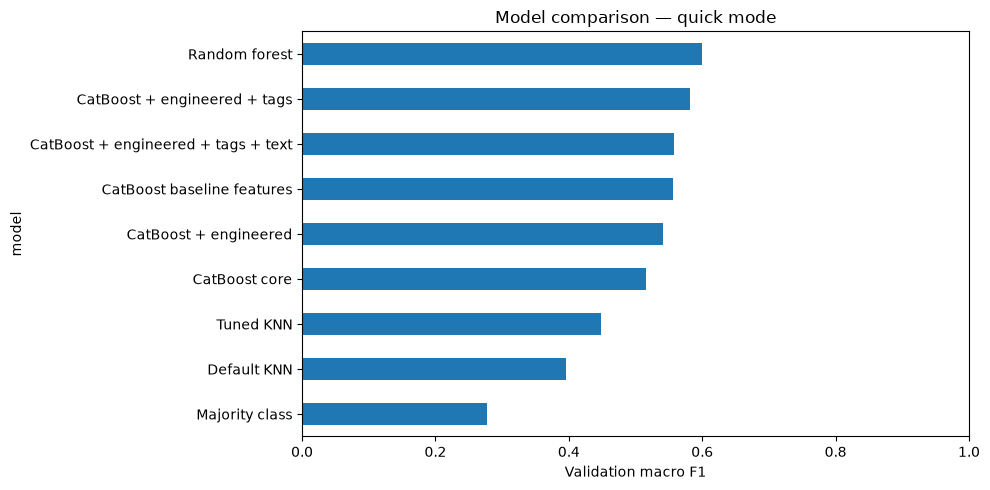

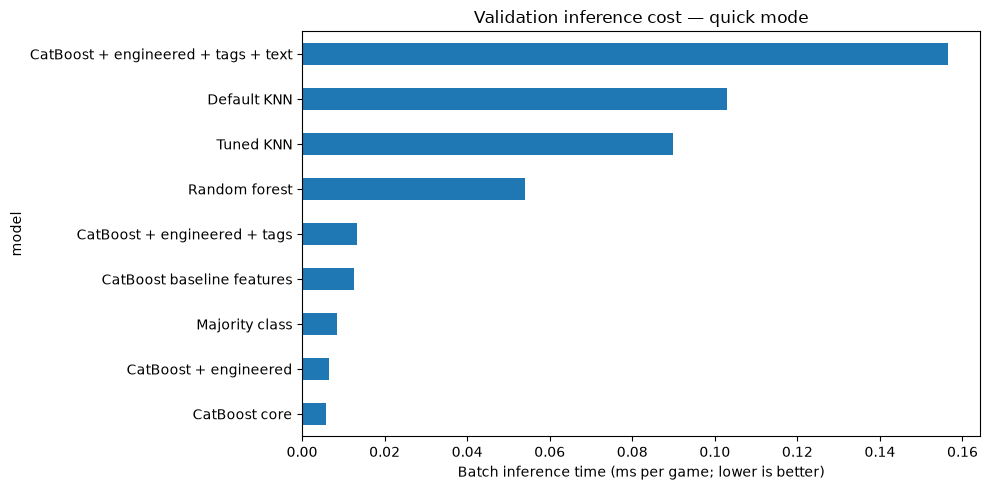

Default KNN
                  precision    recall  f1-score   support

   0–<20k owners       0.74      0.96      0.84      1065
20k–<100k owners       0.32      0.09      0.14       272
100k–200m owners       0.50      0.13      0.20       163

        accuracy                           0.71      1500
       macro avg       0.52      0.39      0.40      1500
    weighted avg       0.64      0.71      0.64      1500

Random forest
                  precision    recall  f1-score   support

   0–<20k owners       0.84      0.89      0.86      1065
20k–<100k owners       0.39      0.29      0.33       272
100k–200m owners       0.60      0.61      0.60       163

        accuracy                           0.75      1500
       macro avg       0.61      0.60      0.60      1500
    weighted avg       0.73      0.75      0.74      1500



In [12]:
comparison = pd.DataFrame(records).set_index("model").sort_values(
    ["macro_f1", "ordinal_rmse", "inference_ms_per_game"], ascending=[False, True, True])
comparison.to_csv(OUTPUT / "validation_comparison.csv")
cv_comparison = pd.DataFrame(cv_summary_records).set_index("model")
cv_comparison.to_csv(OUTPUT / "five_fold_comparison.csv")
display(cv_comparison[["cv_mean_macro_f1", "cv_std_macro_f1",
                       "cv_mean_balanced_accuracy", "cv_mean_inference_ms_per_game",
                       "cv_std_inference_ms_per_game"]].round(4))
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
comparison["macro_f1"].sort_values().plot.barh(ax=ax)
ax.set(xlabel="Validation macro F1", xlim=(0, 1), title=f"Model comparison — {RUN_LABEL} mode")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10, 5))
comparison["inference_ms_per_game"].sort_values().plot.barh(ax=ax)
ax.set(xlabel="Batch inference time (ms per game; lower is better)",
       title=f"Validation inference cost — {RUN_LABEL} mode")
plt.tight_layout(); plt.show()
for name in ["Default KNN", comparison.index[0]]:
    print(name)
    print(classification_report(y_val, validation_predictions[name], labels=CLASSES,
                                target_names=CLASS_NAMES, zero_division=0))

## 10. CatBoost hyperparameter tuning

Use the engineered + tags CatBoost feature set selected for the business shortlist from development results, then search depth, learning rate, iterations, L2 regularization and class weighting on the combined development sample. No early stopping uses the test set. Fold-local pipelines prevent vocabulary leakage.

Compare the selected CatBoost's earlier validation score against the other algorithms. Final CatBoost tuning is a requested experiment, not an assumption that CatBoost must win. Before accessing test labels, freeze the final family by comparing the **pre-tuning validation** winner: if a non-CatBoost model wins, retain it. Tuning CV scores are not directly comparable to held-out validation scores.

Section 11 then tunes Random Forest. If Random Forest was the validation-winning family, its tuned configuration is adopted only when it beats the fixed forest on the same development CV splits.

In [ ]:
# Pin the CatBoost feature variant to the business shortlist chosen from development results.
selected_cat_name = "CatBoost + engineered + tags"
pre_tuning_winner = comparison.index[0]
print("CatBoost feature set for tuning:", selected_cat_name)
print("Frozen final model family (validation winner):", pre_tuning_winner)
cat_parameters = {
    "model__depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.08, 0.15],
    "model__iterations": [20] if SMOKE_TEST else ([250, 450] if QUICK_RUN else [500, 800, 1200]),
    "model__l2_leaf_reg": [3, 7, 12],
    # CatBoost expects the string "None"; Python None is serialized as JSON null and fails.
    "model__auto_class_weights": ["None", "Balanced", "SqrtBalanced"],
}
cat_search, cat_seconds = run_search("catboost_final", make_cat(**cat_variants[selected_cat_name]),
    cat_parameters, CAT_SEARCH_ITER, X.loc[dev_ids], y.loc[dev_ids])
if pre_tuning_winner in cat_variants:
    final_template = clone(cat_search.best_estimator_)
    final_name = f"Tuned {selected_cat_name}"
else:
    final_template = clone(fitted[pre_tuning_winner])
    final_name = pre_tuning_winner
print("Frozen final candidate:", final_name)
# Save configuration before test evaluation. No full-data retraining of other candidates.
packages = ["numpy", "pandas", "scikit-learn", "catboost", "scipy"]
manifest = {
    "run_mode": RUN_LABEL, "seed": SEED, "observation_date": str(OBSERVATION_DATE.date()),
    "dataset_file": DATA_PATH.name, "dataset_version": dataset_metadata["dataset_version"],
    "dataset_sha256": dataset_sha256, "dataset_manifest_sha256": file_sha256(DATA_MANIFEST_PATH),
    "source_dataset_sha256": dataset_metadata.get("source_sha256"),
    "python": platform.python_version(),
    "versions": {p: importlib.metadata.version(p) for p in packages},
    "train_rows": len(train_ids), "validation_rows": len(val_ids), "test_rows": len(test_ids),
    "development_sample_rows": len(dev_ids), "final_refit_rows": len(dev_ids) if SMOKE_TEST else len(full_dev_ids),
    "knn_search_iterations": KNN_SEARCH_ITER, "cat_search_iterations": CAT_SEARCH_ITER,
    "cv_folds": CV_FOLDS, "catboost_feature_variant": selected_cat_name,
    "inference_timing": {"repeats": INFERENCE_REPEATS, "warmup_rows": 1,
                         "aggregation": "median full-batch wall time", "includes_preprocessing": True},
    "knn_best_parameters": knn_search.best_params_,
    "catboost_best_parameters": cat_search.best_params_,
    "validation_winner": pre_tuning_winner, "final_model": final_name,
    "class_names": CLASS_NAMES,
    "preprocessing_notebook": "assessment_1_modeling/notebooks/mle-proccess-data-extra.ipynb",
    "preprocessing_cleaning_report": str(DATA_PATH.with_suffix(".cleaning-report.csv").relative_to(ROOT)),
    "feature_catalog": "feature_catalog.csv",
    "selection_metric": "validation macro F1; ordinal RMSE and latency break ties",
}
(OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))

## 11. Random Forest hyperparameter tuning

Tune the forest after final CatBoost tuning, using the same combined development rows and **5-fold stratified CV**. Keep the section 7 feature set (numeric + genres + tags) so this isolates hyperparameters rather than changing features. Preprocessing is fitted inside each fold; neither the reserved test rows nor test scores participate.

Search tree count, depth, split/leaf size, feature sampling, class weighting and bootstrap sample fraction. The search has **8 candidates in quick mode**, **32 in full mode**, and 2 small candidates for execution checks. `bootstrap=True` is fixed because `max_samples` requires it ([scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)). Search-level parallelism remains 1; each forest uses `N_JOBS` workers.

Re-evaluate the original fixed forest on these development folds before comparing it with the tuned forest and tuned CatBoost. Section 7 used the smaller training subset, so its earlier CV numbers are not a paired tuning comparison. Report all predictive metrics, mean/std inference time and the macro-F1 change against the fixed forest. Best-candidate CV scores are post-selection diagnostics, not final generalization estimates.

The model family remains the validation winner fixed in section 10. If that family is Random Forest, use whichever forest configuration wins development CV macro F1 (ties: ordinal RMSE, then inference time). If tuning does not improve on the fixed forest, retain the fixed configuration. Other winning families retain their section 10 candidate. Freeze the resulting choice and manifest before opening the test set.

In [ ]:
# Defined here so this section can be run after the existing section 10 without rerunning configuration.
RF_SEARCH_ITER = 2 if SMOKE_TEST else (8 if QUICK_RUN else 32)
rf_parameters = {
    "model__n_estimators": [20, 40] if SMOKE_TEST else ([200, 400] if QUICK_RUN else [400, 800]),
    "model__max_depth": [None, 12, 24, 40],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", 0.3, 0.6],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
    "model__max_samples": [None, 0.7, 0.9],
}
rf_tuning_pipeline = clone(forest).set_params(model__bootstrap=True)
rf_search, rf_seconds = run_search("random_forest_final", rf_tuning_pipeline, rf_parameters,
                                  RF_SEARCH_ITER, X.loc[dev_ids], y.loc[dev_ids])

# A paired fixed-forest reference on the SAME development rows/folds as both final searches.
start = perf_counter()
rf_fixed_scores = cross_validate(clone(forest), X.loc[dev_ids], y.loc[dev_ids], cv=cv,
    scoring=score_cv, n_jobs=1, error_score="raise", return_train_score=False)
rf_fixed_seconds = perf_counter() - start
pd.DataFrame(rf_fixed_scores).assign(fold=np.arange(1, CV_FOLDS + 1)).to_csv(
    OUTPUT / "random_forest_fixed_development_folds.csv", index=False)

def final_cv_summary(name, elapsed, *, search=None, fold_scores=None):
    row = {"model": name, "evaluation_or_search_seconds": elapsed}
    predictive_metrics = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1",
                          "ordinal_mae", "ordinal_rmse", "extreme_error_rate"]
    for metric in predictive_metrics + ["neg_inference_seconds", "neg_inference_ms_per_game"]:
        if search is not None:
            index = search.best_index_
            mean = float(search.cv_results_[f"mean_test_{metric}"][index])
            std = float(search.cv_results_[f"std_test_{metric}"][index])
        else:
            values = np.asarray(fold_scores[f"test_{metric}"])
            mean, std = float(values.mean()), float(values.std())
        if metric.startswith("neg_"):
            metric, mean = metric.removeprefix("neg_"), -mean
        row[f"cv_mean_{metric}"] = mean
        row[f"cv_std_{metric}"] = std
    return row

final_tuning_comparison = pd.DataFrame([
    final_cv_summary("Fixed random forest", rf_fixed_seconds, fold_scores=rf_fixed_scores),
    final_cv_summary("Tuned random forest", rf_seconds, search=rf_search),
    final_cv_summary(f"Tuned {selected_cat_name}", cat_seconds, search=cat_search),
]).set_index("model")
final_tuning_comparison["macro_f1_change_vs_fixed_forest"] = (
    final_tuning_comparison["cv_mean_macro_f1"]
    - final_tuning_comparison.loc["Fixed random forest", "cv_mean_macro_f1"])
final_tuning_comparison.to_csv(OUTPUT / "final_tuning_comparison.csv")
display(final_tuning_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
final_tuning_comparison["cv_mean_macro_f1"].plot.barh(
    xerr=final_tuning_comparison["cv_std_macro_f1"], ax=axes[0], capsize=3)
axes[0].set(xlabel="Development CV macro F1 (mean ± fold std)", xlim=(0, 1))
final_tuning_comparison["cv_mean_inference_ms_per_game"].plot.barh(
    xerr=final_tuning_comparison["cv_std_inference_ms_per_game"], ax=axes[1], capsize=3)
axes[1].set(xlabel="Development CV inference (ms/game; lower is better)")
plt.tight_layout(); plt.show()

rf_configuration = final_tuning_comparison.loc[["Fixed random forest", "Tuned random forest"]].sort_values(
    ["cv_mean_macro_f1", "cv_mean_ordinal_rmse", "cv_mean_inference_ms_per_game"],
    ascending=[False, True, True]).index[0]
if pre_tuning_winner == "Random forest":
    final_template = clone(rf_search.best_estimator_ if rf_configuration == "Tuned random forest" else forest)
    final_name = "Tuned random forest" if rf_configuration == "Tuned random forest" else "Random forest"
print("Random Forest configuration selected by development CV:", rf_configuration)
print("Frozen final candidate for test evaluation:", final_name)

manifest.update({
    "rf_search_iterations": RF_SEARCH_ITER,
    "random_forest_best_parameters": rf_search.best_params_,
    "random_forest_selected_configuration": rf_configuration,
    "random_forest_tuning_features": {"engineered": False, "tags": True, "text": False},
    "final_tuning_comparison": "final_tuning_comparison.csv",
    "final_model": final_name,
    "forest_configuration_selection": "development CV macro F1; ordinal RMSE and inference time break ties",
})
(OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))

## 12. Final held-out test evaluation — per-category business comparison

Freeze the three-model shortlist before inspecting test labels:
1. **Tuned CatBoost + engineered + tags** from section 10.
2. **Random forest**, the fixed configuration from section 7.
3. **Tuned random forest** from section 11, even if the fixed forest won the development CV comparison.

Refit each on the same non-test rows and evaluate on the same held-out test games. Keep the default-KNN/majority references and the preselected deployment candidate if it is outside this shortlist. Quick mode selects hyperparameters on a smaller development sample, then refits on all non-test rows; smoke mode uses small samples strictly to validate execution.

Confusion matrices show **actual categories on rows and predicted categories on columns**. Counts show how many games move between categories. Row-normalized values show each actual category's recall; the red outline highlights the actual **100k+ owners** row. A separate table reports precision, recall, F1 and support for every category and model.

For clients prioritizing high-ownership games:
- **High-owner recall:** of actual 100k+ games, how many were identified? Low recall means missed partnership opportunities.
- **High-owner precision:** of games flagged as 100k+, how many were actually in that band? Low precision means more unproductive follow-up.
- Report the number of missed high-owner games, including those incorrectly predicted in the lowest band, alongside false high-owner flags.

The highest band covers **100k–200 million owners**, not just the very largest titles. Category performance is not an estimate of exact downloads or partnership returns. Missing-category recall is shown as NaN, rather than treating an unobserved class as measured performance.

The test set is used only here for final reporting. Keep the previously selected deployment model frozen; do not tune class weights, thresholds or model choice against these results. A future business decision rule that prioritizes high-owner recall should be selected on development CV/validation and evaluated on a fresh holdout. Bootstrap intervals below condition on the fitted model and test sample, not retraining or dataset-shift uncertainty.

Overall test metrics (model choice remains frozen):


,accuracy,balanced_accuracy,macro_f1,weighted_f1,ordinal_mae,ordinal_rmse,extreme_error_rate,fit_seconds,inference_seconds,inference_std_seconds,inference_ms_per_game,inference_games_per_second,inference_batch_size,predict_ms_per_game
model,,,,,,,,,,,,,,
Tuned CatBoost + engineered + tags,0.7723,0.6401,0.6391,0.7628,0.2583,0.5653,0.0306,4.3373,0.1072,0.0026,0.0091,109325.0541,11723,0.0091
Random forest,0.7662,0.6403,0.6392,0.7604,0.2648,0.5716,0.0310,14.5298,0.1881,0.0025,0.0160,62319.3994,11723,0.0160
Tuned random forest,0.7411,0.6543,0.6331,0.7493,0.2909,0.5957,0.0320,32.0046,0.1660,0.0030,0.0142,70611.8264,11723,0.0142
Default KNN reference,0.7356,0.4434,0.4672,0.6795,0.3291,0.6771,0.0647,0.3732,10.3559,0.5299,0.8834,1132.0146,11723,0.8834
Majority reference,0.7087,0.3333,0.2765,0.5879,0.3973,0.7806,0.1060,0.3895,0.0912,0.0034,0.0078,128574.1260,11723,0.0078


Per-category test performance for the three-model shortlist:


category  support  \
model                              class_id                              
Tuned CatBoost + engineered + tags 0            0–<20k owners     8308   
                                   1         20k–<100k owners     2172   
                                   2         100k–200m owners     1243   
Random forest                      0            0–<20k owners     8308   
                                   1         20k–<100k owners     2172   
                                   2         100k–200m owners     1243   
Tuned random forest                0            0–<20k owners     8308   
                                   1         20k–<100k owners     2172   
                                   2         100k–200m owners     1243   

                                             predicted_count  true_positive  \
model                              class_id                                   
Tuned CatBoost + engineered + tags 0                    8715           7459   
                                   1                    1654            758   
                                   2                    1354            837   
Random forest                      0                    8558           7344   
                                   1                    1838            816   
                                   2                    1327            822   
Tuned random forest                0                    7747           6845   
                                   1                    2486            999   
                                   2                    1490            844   

                                             false_negative  false_positive  \
model                              class_id                                   
Tuned CatBoost + engineered + tags 0                    849            1256   
                                   1                   1414             896   
                                   2                    406             517   
Random forest                      0                    964            1214   
                                   1                   1356            1022   
                                   2                    421             505   
Tuned random forest                0                   1463             902   
                                   1                   1173            1487   
                                   2                    399             646   

                                             precision  recall      f1  
model                              class_id                             
Tuned CatBoost + engineered + tags 0            0.8559  0.8978  0.8763  
                                   1            0.4583  0.3490  0.3962  
                                   2            0.6182  0.6734  0.6446  
Random forest                      0            0.8581  0.8840  0.8709  
                                   1            0.4440  0.3757  0.4070  
                                   2            0.6194  0.6613  0.6397  
Tuned random forest                0            0.8836  0.8239  0.8527  
                                   1            0.4019  0.4599  0.4289  
                                   2            0.5664  0.6790  0.6176

Preselected deployment model: Random forest


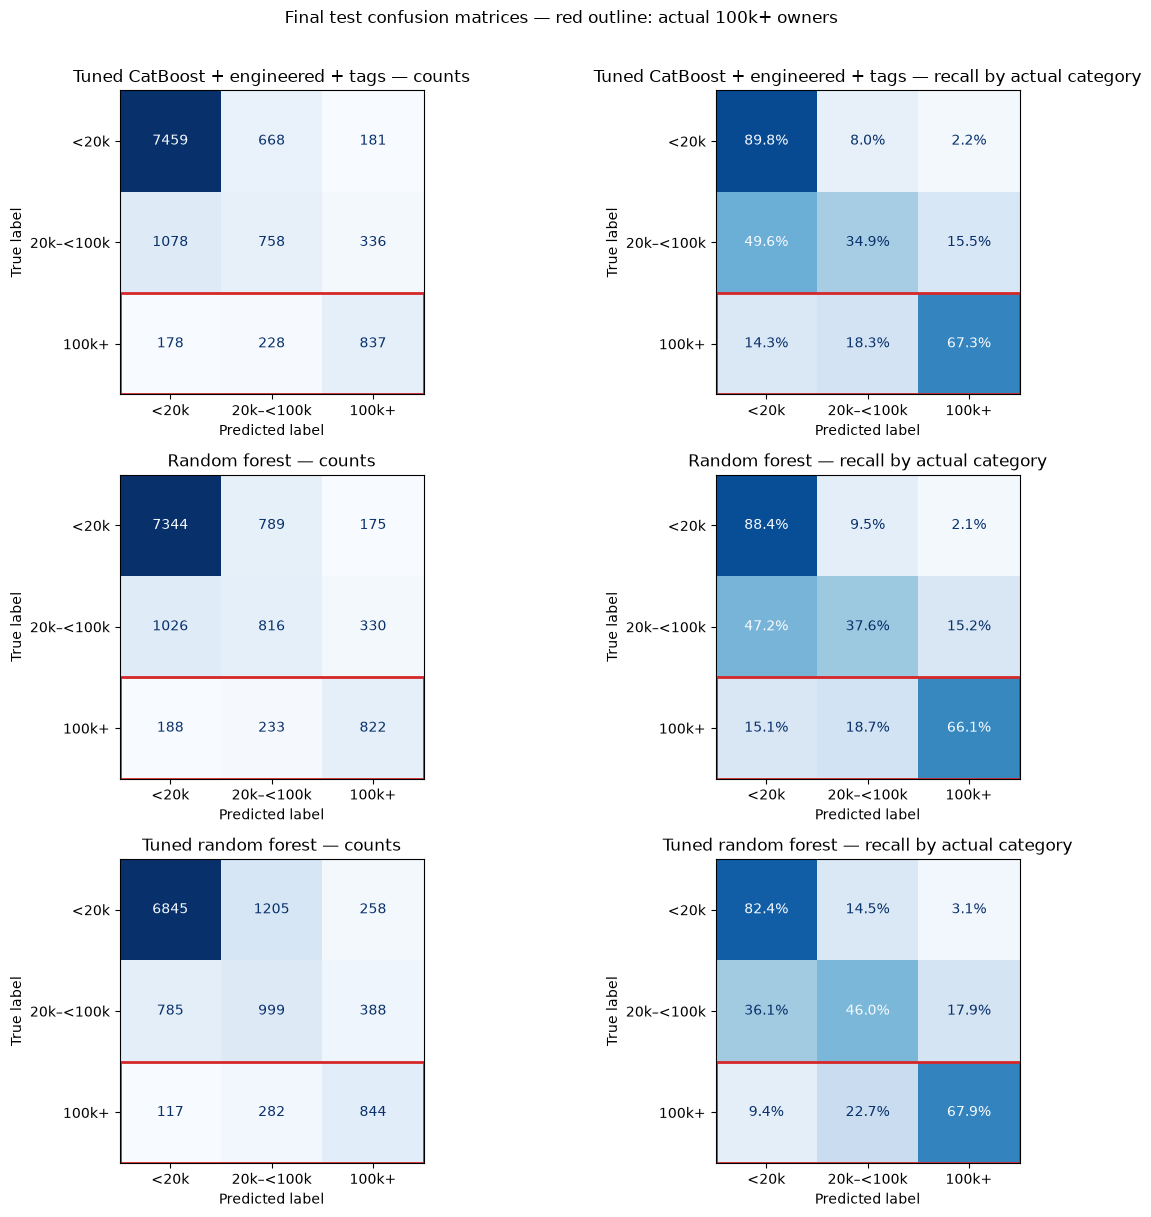

Business focus: actual 100k+ games identified/missed, and precision of high-owner flags:


,category,actual_high_owner_games,flagged_high_owner_games,identified_high_owner_games,missed_high_owner_games,false_high_owner_flags,high_owner_precision,high_owner_recall,high_owner_f1,high_owner_predicted_lowest_band,inference_ms_per_game
model,,,,,,,,,,,
Tuned CatBoost + engineered + tags,100k–200m owners,1243,1354,837,406,517,0.6182,0.6734,0.6446,178,0.0091
Random forest,100k–200m owners,1243,1327,822,421,505,0.6194,0.6613,0.6397,188,0.0160
Tuned random forest,100k–200m owners,1243,1490,844,399,646,0.5664,0.6790,0.6176,117,0.0142


In [17]:
from sklearn.metrics import confusion_matrix
from matplotlib.patches import Rectangle

SHORTLIST_MODELS = ["Tuned CatBoost + engineered + tags", "Random forest", "Tuned random forest"]
HIGH_OWNER_CLASS = 2
SHORT_CLASS_NAMES = ["<20k", "20k–<100k", "100k+"]
if selected_cat_name != "CatBoost + engineered + tags":
    raise ValueError("Rerun section 10 for the engineered + tags CatBoost variant before evaluating this shortlist.")

refit_ids = dev_ids if SMOKE_TEST else full_dev_ids
X_refit, y_refit = X.loc[refit_ids], y.loc[refit_ids]
final_models = {
    "Tuned CatBoost + engineered + tags": clone(cat_search.best_estimator_),
    "Random forest": clone(forest),
    "Tuned random forest": clone(rf_search.best_estimator_),
    "Default KNN reference": clone(default_knn),
    "Majority reference": Pipeline([("features", make_preprocessor()),
                                   ("model", DummyClassifier(strategy="most_frequent"))]),
}
selected_test_model_name = final_name
if selected_test_model_name not in final_models:
    final_models[selected_test_model_name] = clone(final_template)
# Persist the evaluation set and deployment choice BEFORE opening test labels.
manifest.update({"final_test_models": list(final_models), "business_shortlist": SHORTLIST_MODELS,
    "selected_test_model": selected_test_model_name, "high_owner_class": HIGH_OWNER_CLASS,
    "test_used_for_model_selection": False,
    "per_category_metrics": "final_test_category_metrics.csv",
    "high_owner_summary": "final_test_high_owner_summary.csv",
    "confusion_matrices": "final_test_confusion_matrices.csv"})
(OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
X_test, y_test = X.loc[test_ids], y.loc[test_ids]


def per_category_report(truth, prediction):
    truth, prediction = np.asarray(truth), np.asarray(prediction).reshape(-1)
    if (len(truth) != len(prediction) or not np.isin(truth, CLASSES).all()
            or not np.isin(prediction, CLASSES).all()):
        raise ValueError("Category reporting requires matching arrays of known class labels.")
    counts = confusion_matrix(truth, prediction, labels=CLASSES)
    actual = counts.sum(axis=1)
    predicted = counts.sum(axis=0)
    correct = np.diag(counts)
    table = pd.DataFrame({
        "class_id": CLASSES, "category": CLASS_NAMES, "support": actual,
        "predicted_count": predicted, "true_positive": correct,
        "false_negative": actual - correct, "false_positive": predicted - correct,
        "precision": np.divide(correct, predicted, out=np.zeros(len(CLASSES), dtype=float), where=predicted > 0),
        "recall": np.divide(correct, actual, out=np.full(len(CLASSES), np.nan), where=actual > 0),
        "f1": np.divide(2 * correct, actual + predicted, out=np.zeros(len(CLASSES), dtype=float),
                        where=(actual + predicted) > 0),
    })
    return table, counts


test_records, test_predictions, category_records, test_confusions = [], {}, [], {}
for name, estimator in final_models.items():
    start = perf_counter(); estimator.fit(X_refit, y_refit); fit_seconds = perf_counter() - start
    pred, inference = benchmark_inference(estimator, X_test)
    test_predictions[name] = pred
    test_records.append({"model": name, **metrics(y_test, pred),
                         "fit_seconds": fit_seconds, **inference,
                         "predict_ms_per_game": inference["inference_ms_per_game"]})
    categories, counts = per_category_report(y_test, pred)
    category_records.append(categories.assign(model=name))
    test_confusions[name] = counts

test_results = pd.DataFrame(test_records).set_index("model")
category_results = pd.concat(category_records, ignore_index=True).set_index(["model", "class_id"])
test_results.to_csv(OUTPUT / "final_test_metrics.csv")
category_results.to_csv(OUTPUT / "final_test_category_metrics.csv")
print("Overall test metrics (model choice remains frozen):")
display(test_results.round(4))
print("Per-category test performance for the three-model shortlist:")
display(category_results.loc[SHORTLIST_MODELS].round(4))
print("Preselected deployment model:", selected_test_model_name)

# Store counts, row-normalized recall and column-normalized precision for every evaluated model.
confusion_rows = []
for name, counts in test_confusions.items():
    for i, actual_class in enumerate(CLASSES):
        for j, predicted_class in enumerate(CLASSES):
            row_total, column_total = counts[i].sum(), counts[:, j].sum()
            confusion_rows.append({"model": name, "actual_class": actual_class,
                "predicted_class": predicted_class, "count": int(counts[i, j]),
                "row_fraction": counts[i, j] / row_total if row_total else np.nan,
                "column_fraction": counts[i, j] / column_total if column_total else np.nan})
pd.DataFrame(confusion_rows).to_csv(OUTPUT / "final_test_confusion_matrices.csv", index=False)

fig, axes = plt.subplots(len(SHORTLIST_MODELS), 2, figsize=(13, 4 * len(SHORTLIST_MODELS)), squeeze=False)
for row, name in enumerate(SHORTLIST_MODELS):
    for column, normalization in enumerate([None, "true"]):
        ax = axes[row, column]
        ConfusionMatrixDisplay.from_predictions(y_test, test_predictions[name], labels=CLASSES,
            display_labels=SHORT_CLASS_NAMES, normalize=normalization, ax=ax, cmap="Blues", colorbar=False,
            values_format=".1%" if normalization else "d",
            im_kw={"vmin": 0, "vmax": 1} if normalization else None)
        ax.set_title(name + (" — counts" if normalization is None else " — recall by actual category"))
        ax.add_patch(Rectangle((-0.5, HIGH_OWNER_CLASS - 0.5), len(CLASSES), 1,
                               fill=False, edgecolor="tab:red", linewidth=2))
fig.suptitle("Final test confusion matrices — red outline: actual 100k+ owners", y=1.01)
plt.tight_layout()
fig.savefig(OUTPUT / "final_test_shortlist_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

high_owner_summary = category_results.xs(HIGH_OWNER_CLASS, level="class_id").loc[SHORTLIST_MODELS].copy()
high_owner_summary = high_owner_summary.rename(columns={
    "support": "actual_high_owner_games", "predicted_count": "flagged_high_owner_games",
    "true_positive": "identified_high_owner_games", "false_negative": "missed_high_owner_games",
    "false_positive": "false_high_owner_flags", "precision": "high_owner_precision",
    "recall": "high_owner_recall", "f1": "high_owner_f1"})
high_owner_summary["high_owner_predicted_lowest_band"] = [
    int(test_confusions[name][CLASSES.index(HIGH_OWNER_CLASS), 0]) for name in SHORTLIST_MODELS]
high_owner_summary["inference_ms_per_game"] = test_results.loc[SHORTLIST_MODELS, "inference_ms_per_game"]
high_owner_summary.to_csv(OUTPUT / "final_test_high_owner_summary.csv")
print("Business focus: actual 100k+ games identified/missed, and precision of high-owner flags:")
display(high_owner_summary.round(4))

prediction_table = pd.DataFrame({"AppID": frame.loc[test_ids, "AppID"].to_numpy(),
                                 "truth": y_test.to_numpy(), **test_predictions})
prediction_table.to_csv(OUTPUT / "test_predictions.csv", index=False)

In [18]:
rng = np.random.default_rng(SEED)
truth = y_test.to_numpy()
chosen = test_predictions[selected_test_model_name]
reference = test_predictions["Default KNN reference"]
bootstrap = []
for _ in range(30 if SMOKE_TEST else 500):
    sampled = np.concatenate([rng.choice(np.flatnonzero(truth == c),
        size=np.sum(truth == c), replace=True) for c in CLASSES])
    chosen_f1 = f1_score(truth[sampled], chosen[sampled], labels=CLASSES, average="macro", zero_division=0)
    baseline_f1 = f1_score(truth[sampled], reference[sampled], labels=CLASSES, average="macro", zero_division=0)
    bootstrap.append([chosen_f1, chosen_f1 - baseline_f1])
intervals = pd.DataFrame(np.quantile(bootstrap, [0.025, 0.975], axis=0).T,
    columns=["95% lower", "95% upper"], index=["Candidate macro F1", "Macro F1 change vs default KNN"])
display(intervals.round(4))
intervals.to_csv(OUTPUT / "bootstrap_intervals.csv")

,95% lower,95% upper
Candidate macro F1,0.6278,0.6493
Macro F1 change vs default KNN,0.1593,0.1873


## 13. Evidence for the board and next production phase

The summary below compares the currently selected test model with **Tuned CatBoost + engineered + tags**, using their measured results from section 12. If CatBoost is already the selected model, it appears only once. This adds a board-reporting comparison; the preselected deployment model and section 14 export choice remain unchanged. A macro-F1 gain is evidence of better class prediction on this holdout, not evidence of increased partnerships or downloads. Define the costs of missed popular games versus overestimated games with stakeholders before selecting a business decision threshold.

Before production: validate a release-time or developer-group split; obtain dated pre-launch features if forecasting is required; define a prediction horizon; verify tag availability; assess calibration and segment performance; package the complete feature/model pipeline behind a versioned input schema; test training-serving consistency, latency and memory; and monitor drift and class recall. This notebook does not deploy or package a service.

In [20]:
# Report both models without replacing the deployment choice made before test evaluation.
selected_test_model_names = list(dict.fromkeys([
    selected_test_model_name,
    "Tuned CatBoost + engineered + tags",
]))
missing_models = [name for name in selected_test_model_names if name not in test_results.index]
if missing_models:
    raise ValueError(f"Run section 12 before generating the board summary; missing models: {missing_models}")
base = test_results.loc["Default KNN reference"]


def board_model_summary(model_name):
    model = test_results.loc[model_name]
    high_owner = category_results.loc[(model_name, HIGH_OWNER_CLASS)]
    return pd.Series({
        "Experiment mode": RUN_LABEL,
        "Prediction target": "Cumulative estimated-owner band",
        "Model": model_name,
        "Preselected deployment model": "Yes" if model_name == selected_test_model_name else "No",
        "Final training games": len(refit_ids),
        "Test games": len(test_ids),
        "Default KNN macro F1": f"{base['macro_f1']:.3f}",
        "Macro F1": f"{model['macro_f1']:.3f}",
        "Macro F1 change vs default KNN": f"{model['macro_f1'] - base['macro_f1']:+.3f}",
        "Balanced accuracy": f"{model['balanced_accuracy']:.3f}",
        "Extreme-class error rate": f"{model['extreme_error_rate']:.1%}",
        "Default KNN inference (ms/game)": f"{base['inference_ms_per_game']:.4f}",
        "Inference (ms/game)": f"{model['inference_ms_per_game']:.4f}",
        "Inference batch (seconds)": f"{model['inference_seconds']:.4f}",
        "Throughput (games/second)": f"{model['inference_games_per_second']:.1f}",
        "100k+ owner recall": f"{high_owner['recall']:.1%}",
        "100k+ owner precision": f"{high_owner['precision']:.1%}",
        "100k+ owner F1": f"{high_owner['f1']:.3f}",
        "Actual 100k+ games": int(high_owner['support']),
        "100k+ games correctly identified": int(high_owner['true_positive']),
        "Actual 100k+ games missed": int(high_owner['false_negative']),
        "False 100k+ owner flags": int(high_owner['false_positive']),
    }, name=model_name)


summary = pd.concat([board_model_summary(name) for name in selected_test_model_names], axis=1)
summary = summary.rename_axis("Measure").reset_index()
display(summary)
summary.to_csv(OUTPUT / "board_summary.csv", index=False)
if SMOKE_TEST:
    print("SMOKE TEST ONLY: these small-sample scores validate execution and must not be presented as model performance.")
elif QUICK_RUN:
    print("Exploratory run: tuning used a capped development sample. Run QUICK_RUN=False before making a final recommendation.")
print("Results saved to:", OUTPUT)

,Measure,Random forest,Tuned CatBoost + engineered + tags
0,Experiment mode,quick,quick
1,Prediction target,Cumulative estimated-owner band,Cumulative estimated-owner band
2,Model,Random forest,Tuned CatBoost + engineered + tags
3,Preselected deployment model,Yes,No
4,Final training games,46891,46891
5,Test games,11723,11723
6,Default KNN macro F1,0.467,0.467
7,Macro F1,0.639,0.639
8,Macro F1 change vs default KNN,+0.172,+0.172
9,Balanced accuracy,0.640,0.640


Exploratory run: tuning used a capped development sample. Run QUICK_RUN=False before making a final recommendation.
Results saved to: /mnt/c/Workspace3/machine-learning-engineer-amsterdam (29)/artifacts/steam_experiments/quick


## 14. Optional: export the fixed Random Forest to ONNX for production

Assessment 2 uses the **fixed Random Forest** selected from development results. Set `EXPORT_MODEL=True` after final refitting and choose an immutable model version. Export does not train a model or alter the test results. The Random Forest classifier becomes `model.onnx`; its fitted numeric medians and binary genre/tag vocabularies become `preprocessing.json`. Custom tokenization and fixed game/date features stay in shared Python code, rather than being silently omitted from conversion.

The exporter checks raw-input feature parity, preprocessed matrix parity, ONNX probabilities and predicted classes on paired development examples before publishing `manifest.json` with hashes, runtime versions and provenance. Float32 conversion uses an explicit tolerance and rejects class changes on these examples. This is a release gate on a representative sample, not a proof of equality on every future input. Unsupported models, text/scaling configurations and smoke-test exports are rejected. See `assessment_2_production/README.md` for release packaging and `assessment_3_infrastructure/azure-blueprint.md` for private Azure hosting.


In [ ]:
EXPORT_MODEL = False
MODEL_VERSION = "steam-rf-onnx-v1"

if EXPORT_MODEL:
    if SMOKE_TEST:
        raise ValueError("Smoke-test models cannot be released.")
    from steam_service.export import export_model
    from steam_service.features import training_frame_to_games

    # Export the already fitted FIXED forest, independently of the comparison models.
    production_model_name = "Random forest"
    parity_ids = pd.concat([part.sample(min(500, len(part)), random_state=SEED)
                            for _, part in frame.loc[refit_ids].groupby("target")]).index
    model_path = export_model(
        final_models[production_model_name], model_version=MODEL_VERSION,
        training_observation_date=OBSERVATION_DATE.date(),
        validation_games=training_frame_to_games(frame.loc[parity_ids], OBSERVATION_DATE.date()),
        reference_features=X.loc[parity_ids], output_root=ROOT / "models",
        provenance={"experiment_mode": RUN_LABEL, "dataset_sha256": dataset_sha256,
                    "refit_rows": len(refit_ids), "selected_model": production_model_name},
    )
    print("Exported immutable ONNX release:", model_path)
else:
    print("Export disabled. See assessment_2_production/README.md for the ONNX release workflow.")


## 15. Further improvements — plans using the existing data


### Evidence motivating the plan

The saved run uses `QUICK_RUN=True`: hyperparameter searches use a capped **6,000-game development sample**, while final candidates are refitted on **46,891 non-test games**. Expanding the development search therefore differs from simply fitting the final model on more rows.

The final comparison also shows why optimization must follow business priorities. Relative to the fixed forest, the tuned forest identifies **22 additional high-owner games** (844 versus 822) but adds **141 false high-owner flags** (646 versus 505). Tuned CatBoost and the fixed forest have similar overall macro F1, while their errors and inference costs can differ. These observed test results motivate future questions; they must not become a dataset for further tuning.

### Plan 1 — establish full-development learning curves and tuning

**Action:** run `QUICK_RUN=False` and compare fixed Random Forest and the selected CatBoost feature variant on progressively larger, stratified training samples, keeping evaluation folds consistent within each sample-size comparison. Then run the declared full-development searches; expand search budgets only where learning curves or parameter results justify it. For CatBoost, any early-stopping validation must stay inside the training/development procedure.

**Reason:** the current search may select settings suited to 6,000 development games rather than the larger final training population. Learning curves help distinguish a need for more data from model-capacity or feature limitations.

**Evaluate:** five-fold macro F1, high-owner precision/recall, ordinal errors, variability, search cost and complete-pipeline inference time. Compare fixed and tuned configurations on the same rows/folds; retain the simpler configuration if improvement is not repeatable or worth the cost.

### Plan 2 — align the high-owner decision rule with client priorities

**Action:** agree with stakeholders on the relative cost of missed popular games and false flags, or on a minimum acceptable precision/review capacity. Using out-of-fold development probabilities, test thresholds on `P(100k+ owners)`. If a game does not pass the high-owner threshold, define explicitly how its lower-band class is assigned, for example by the larger of the two remaining probabilities. Alternatively, evaluate a separate high-owner review flag alongside the existing three-class prediction.

**Reason:** macro F1 weights all classes equally, whereas clients particularly value high-owner games. Changing a decision rule may improve opportunity coverage without a more complex learner; it can also increase false flags.

**Evaluate:** the precision–recall tradeoff, high-owner F1, flagged workload, missed high-owner games and extreme underestimation, alongside overall macro F1. Select the rule on development data only. This would be a deliberate new selection policy; it does not retroactively change the current experiment's macro-F1 rule. See the [decision-threshold guide](https://scikit-learn.org/stable/modules/classification_threshold.html).

### Plan 3 — give Random Forest comparable engineered inputs

**Action:** compare baseline forest inputs with **Random Forest + the existing engineered features**, using the same development folds and matched model settings first. Then test the 13 additional metadata candidates from `games-extra.parquet` in groups: release-calendar features, metadata/localization counts and missingness indicators. Tune only the feature variants that justify further investigation.

**Reason:** the current forest uses baseline numeric, genre and tag features, while the selected CatBoost variant also has engineered inputs. A matched feature comparison separates the benefit of the learner from the benefit of its representation. Additional columns may be redundant or constant; more features are not automatically better.

**Evaluate:** incremental changes in macro F1 and high-owner precision/recall, supported by paired fold results and inference cost. Fit any learned transformations within folds. Update the serving feature contract only after an expanded feature set is selected.

### Plan 4 — investigate errors and add targeted metadata signals

**Action:** analyze development out-of-fold errors by ownership band, game age, free/paid status, genre, platform and metadata availability. Prioritize the medium band, whose fixed-forest test F1 is approximately **0.407**, and high-owner games assigned to the lowest band. Review a sample of errors to distinguish weak features from uncertain owner labels or inconsistent metadata.

**Reason:** segment analysis can identify concrete deficiencies that broad hyperparameter searches miss. Candidate follow-ups include price-by-age/platform/genre interactions and developer/publisher history. Historical signals must use only information available before each prediction; do not compute an entity's success from the complete labeled dataset. Any target-derived encodings require training-only/out-of-fold construction, with unseen-entity handling.

**Evaluate:** whether segment gains persist across folds without unacceptable losses elsewhere. Report group sizes; small segments can produce unstable conclusions. Keep review counts, playtime and concurrency excluded unless a separately defined prediction-time use case legitimately permits them.

### Plan 5 — test a small Random Forest–CatBoost ensemble

**Action:** first measure agreement and complementary correct predictions on development out-of-fold results. If the models make sufficiently different mistakes, test a weighted probability average. Learn weights on development predictions; any stacking extension must train on out-of-fold base-model predictions rather than their in-sample predictions.

**Reason:** similar aggregate scores can hide complementary errors. An ensemble is worthwhile only if combining the models adds value beyond either model alone.

**Evaluate:** macro F1, high-owner precision/recall, extreme errors, artifact size and the inference cost of executing both pipelines. Compare against the best single model; do not keep the ensemble merely because it is more complex. See the [ensemble guide](https://scikit-learn.org/stable/modules/ensemble.html#voting-classifier).

### Plan 6 — assess and, if needed, calibrate probabilities

**Action:** examine high-owner reliability curves and appropriate multiclass probability losses on development predictions. Compare uncalibrated probabilities with cross-validated calibration, keeping calibration fitting separate from evaluation. If plan 2 uses calibrated probabilities, fit calibration before choosing its decision threshold, using a properly separated development procedure.

**Reason:** the service returns class probabilities, and ranking or decision thresholds depend on how those probabilities behave. Calibration can improve probability interpretation without necessarily improving class F1 or ranking.

**Evaluate:** probability losses, reliability, the resulting high-owner decision tradeoff, and added inference cost. Do not assume a better-calibrated model is a more accurate classifier. See the [calibration guide](https://scikit-learn.org/stable/modules/calibration.html).

### Execution order and acceptance criteria

Start with **plan 1 and the error analysis in plan 4**, then run the feature ablations in plan 3. Assess calibration and the business decision rule together (plans 6 and 2); test the ensemble in plan 5 if out-of-fold errors indicate complementary signal. Agree on acceptable false-flag workload, missed-opportunity tradeoffs and serving cost before accepting a new candidate.

Give further KNN tuning and a larger description TF-IDF vocabulary lower priority: the saved development results favor tree models, and the tested TF-IDF extension reduced CatBoost CV macro F1 while increasing prediction cost. This does not rule out every alternative text representation; it limits what the current evidence supports.

All selection, feature engineering choices, thresholds, calibration and ensemble weights must stay within development evaluation. Because the current test results have already informed these plans, obtain a **fresh untouched holdout** for final confirmation. Add chronological or developer/franchise-group evaluation where appropriate before making future-release or unseen-developer claims. Escalate to the multimodal ideas in section 16 when the incremental gain from these less costly changes is understood.


## 16. Further improvements — screenshots, trailers and multimodal features

### Motivation and scope

`games.csv` contains **`Screenshots`**, **`Movies`** and **`Header image`** URL fields. The current experiments do not use their visual content. Screenshots can convey art style, gameplay perspective, interface complexity and visual presentation; trailers can additionally convey motion, pacing and audio. These are plausible signals of player interest that structured metadata may miss. This is a hypothesis for future experiments: our snapshot data cannot demonstrate that a particular screenshot or trailer caused more downloads.

A URL is a pointer, not an image/video feature. We would need to retrieve and validate the media, define a consistent sampling policy, extract a fixed-size representation per game, and retrain/evaluate a model. The following are alternative starting points, not a requirement to implement every option. Relative costs depend on the encoder, resolution, number of assets, hardware and caching; they are not measured costs for this project.

### Practical choices and their tradeoffs

| Choice | How to use the information | Expected value and relative cost | Main risks / limitations |
| --- | --- | --- | --- |
| **1. Lightweight media metadata and visual statistics** | Add listed screenshot/trailer counts and missingness flags; after retrieval, optionally compute image dimensions, aspect ratio, brightness/color summaries and video duration. Keep raw URL strings and identifiers out of model inputs. | Low-cost starting point; test whether listing completeness or simple presentation attributes add signal. Downloading/decoding is still required for content statistics, even without a neural encoder. | Counts may reflect marketing resources rather than player appeal. Broken links are not evidence of no media. Brightness/resolution does not measure gameplay quality; count features may duplicate existing completeness signals. |
| **2. Frozen screenshot image encoder** | Use a pretrained encoder such as [CLIP](https://github.com/openai/CLIP) or [DINOv2](https://github.com/facebookresearch/dinov2). Encode a capped, deterministic screenshot sample per game, optionally encode the header separately, then mean-pool or otherwise aggregate to one vector per modality. Concatenate with the structured features and train a classifier. | Moderate offline encoding cost, with possible CPU inference for smaller choices or GPU batching for throughput. Reuse cached vectors across model searches, avoiding encoder training in each fold. This is a practical first semantic-content experiment. | Generic representations may not transfer to game art. Pooling can erase important scenes. Familiar franchise logos or recognizable titles may act as identity shortcuts. High-dimensional vectors can overfit or make tree models costly; compare a regularized linear head with the existing tree candidates. |
| **3. Trailer frames with an image encoder** | Sample a fixed number of frames across a capped duration, encode them with the same frozen image encoder, and aggregate frame vectors. Consider combining screenshot and trailer-frame summaries. | A middle ground between screenshot-only and video models. Adds more views of the game while reusing the image-encoding stack. Cost includes video transfer, decoding and one image-model pass per sampled frame. | Frame pooling does not model temporal order or motion. Logos, cinematic scenes and title cards may dominate; sparse sampling can miss gameplay. Frames from the same game must never become separate train/test examples. |
| **4. Structured descriptions from a vision-language model** | Ask an image/video-understanding model for a constrained schema, such as perspective, 2D/3D style, UI density and visible gameplay elements. Store these fields or derived text features; optionally extract OCR text, with separate review for outcome claims. | More human-readable features for error analysis and board explanations. May use a hosted model or a local model; cost depends on asset/token volume, model size and deployment. Cache outputs and version the model, prompt and schema. | Generated attributes can be wrong, inconsistent or biased. OCR may expose “millions of players,” awards or reviews, leaking post-outcome information. Describe visible content rather than asking the model to guess popularity; external knowledge could reproduce the target. Treat media text as data, never instructions. |
| **5. Frozen video encoder** | Sample short clips with consistent frame rate, frame count and resolution, then extract clip embeddings using a model such as [VideoMAE](https://huggingface.co/docs/transformers/model_doc/videomae). Aggregate clips into one game vector; add audio/transcript features only in a separate ablation. | Higher extraction and memory cost in many practical configurations, but potentially captures motion patterns unavailable to independent frame pooling. Benchmark the chosen configuration rather than assuming it is always slower or better. | Pretraining may emphasize real-world actions rather than game footage. Trailers mix gameplay with cinematics and editing; audio/music can be licensed independently. More clips/resolution increase transfer, decode and encoder cost without guaranteed improvement. |
| **6. Adapt an encoder or train a multimodal fusion model** | Fine-tune selected layers/adapters or learn a fusion network over structured, text, screenshot and video representations, using development data only. Start with frozen encoders before considering this step. | Highest development complexity and usually substantially greater training cost; could learn game-specific visual signals and cross-modal interactions if earlier ablations justify it. Parameter-efficient adaptation can reduce trainable parameters, but does not eliminate media processing or validation cost. | Greater overfitting risk with imbalanced labels and correlated game assets; more tuning, GPU memory and training-serving consistency work. Fine-tuning cannot repair missing historical media or a biased target. A complicated system may yield little gain over cached frozen features. |

CLIP provides image/text encoders; DINOv2 provides pretrained visual features. These are examples of representation families, not evidence of superior performance on Steam ownership. VideoMAE is a video-model example, not an ownership predictor. Verify the particular checkpoint's input requirements, training data, license and deployment suitability before adoption.

### Combine modalities without losing the baseline comparison

Start with **early fusion**: join a game's cached visual vector to its existing structured/tag features. For high-dimensional embeddings, compare a regularized linear classifier with CatBoost/Random Forest, and fit any learned scaling, dimensionality reduction or feature selection inside training folds. Preserve the existing feature-only model as the reference.

An alternative is **late fusion**: combine probabilities from separately trained metadata, image and video classifiers. Learn combination weights, calibration or a stacking model from development predictions; stacking inputs must be out-of-fold predictions, not predictions on the same rows used to fit the base learners. Evaluate whether this improves high-owner recall/precision rather than simply adding complexity. Use modality-presence flags and test a defined metadata-only fallback when images/videos are missing. If required multimodal inputs are unavailable, do not silently replace them with arbitrary vectors and present the result as the normal model.

### Data and modeling risks to address

- **Temporal leakage and unavailable history:** URLs can point to assets updated after a game became popular. A download today does not reconstruct the media shown at the July 2023 snapshot or at launch. Store retrieval timestamps and content hashes, and require historically appropriate assets before claiming release-time forecasting. URL query timestamps alone are not reliable proof of historical availability.
- **Popularity, identity and marketing confounding:** logos, recognizable franchises, awards, review quotes and publisher resources can correlate with ownership without explaining visual appeal. Pretrained models may already recognize famous games. Audit such cases and report performance by release cohort, publisher/developer group and ownership band; group splits help but cannot guarantee the absence of pretraining contamination.
- **Near-duplicates and split leakage:** DLCs, sequels and related games may share screenshots or trailers. Keep every asset and derived frame attached to its game, detect duplicate/similar assets, and consider franchise/developer grouping when splitting. More frames do not create more independent labeled games.
- **Availability and selection bias:** downloads can fail, formats can change and some games have richer media than others. Measure URL presence, successful retrieval, usable decoding and coverage by target category separately. Avoid evaluating only games with successful downloads and assuming the result applies to all games.
- **Media quality and domain shift:** trailer editing may not represent gameplay; visual trends and generative promotional assets can change. Audit sampled assets and model errors, monitor embedding/availability drift, and evaluate whether gains persist on newer releases. Media signals do not establish player exposure or purchase motivation.
- **Asset handling and reproducibility:** use bounded, validated retrieval/decoding with URL/network restrictions, timeouts and file-size/frame limits; review allowed use and storage of assets and model checkpoints. Keep the asset hash, encoder/checkpoint version, preprocessing, frame selection and pooling policy with each feature artifact. Do not use remote URLs as uncontrolled synchronous inputs to the prediction service.

### Compute costs and a production approach

A useful planning approximation is:

`image passes ≈ games × (screenshots per game + trailers per game × sampled frames per trailer)`

For illustration only, **60,000 games × (5 screenshots + 1 trailer × 16 frames) = 1.26 million image passes** for an image/frame approach, excluding header images. This is not a measured runtime estimate, and a video encoder instead processes clip tensors with different cost. Float32 storage for one pooled 768-dimensional vector per game would be about **184 MB** for 60,000 games, before indexes, additional modalities and replicas; retained media and unpooled vectors can be much larger.

Prefer a separate **offline/asynchronous extraction job** that retrieves assets once, computes embeddings and stores versioned per-game features. The FastAPI path can then use a cached representation and a lightweight classifier. For a new game with uncached media, return an explicit pending status or use the validated metadata-only fallback while an extraction job runs. This requires a deliberate API/feature-schema update; the current service does not implement media ingestion.

Benchmark two distinct costs: **cold ingestion** (download, decode, encode and storage) and **warm prediction** (feature lookup, preprocessing and classifier). Report end-to-end single-request latency distributions such as p50/p95, throughput under load, memory/VRAM, feature freshness, failure/fallback rates and cost per newly processed game. Current notebook batch inference timings omit media extraction and HTTP overhead, so they cannot represent the total cost of a multimodal service. Caching moves encoder work out of the request path; it does not eliminate that cost.

### Suggested order for future experiments

1. Audit media availability and historical suitability, then establish the lightweight metadata baseline.
2. Pilot frozen screenshot embeddings on a representative development sample; compare metadata-only versus metadata-plus-images on identical games and folds.
3. Add sampled trailer frames only if image features help; evaluate each added modality separately before trying temporal video encoders or fine-tuning.
4. Compare predictive gains using macro F1, balanced accuracy, high-owner precision/recall/F1, severe underestimation and resource costs. Report both complete-media subsets and realistic missing-media/fallback scenarios.
5. Agree on acceptable missed-opportunity/false-flag tradeoffs and a compute budget using development data. Since the existing holdout has already informed this project, obtain a fresh untouched holdout for final confirmation; use chronological or grouped evaluation where appropriate.

Advance to more expensive encoders only when the incremental business-relevant gain is repeatable and worth its extraction, storage and serving costs. None of these ideas has been implemented or evaluated in the current notebook.
